# Marketing Campaign Analysis
### Channel performance, personalization A/B test and House Ads conversion drop (January 2018)

---

## Contents
1. [Project Overview](#overview)
2. [Setup & Data Loading](#setup)
3. [Data Cleaning](#cleaning)
4. [Exploratory Data Analysis](#eda)
5. [Retention Rate](#retention)
6. [Conversion Analysis by Age Group, Channel and Day of Week](#segments)
7. [Deep Dive: House Ads Conversion Drop](#houseads)
8. [A/B Testing: Personalization vs. Control](#abtest)
9. [Final Conclusions & Recommendations](#conclusions)

<a id="overview"></a>
## 1. Project Overview

**Objective.** Evaluate how marketing campaigns performed across channels, age groups and test groups (control vs. personalization), and investigate the reasons behind over- and under-performance of individual channels.

**Dataset.** One month of campaign data (1–31 January 2018): 10,037 records with marketing channel, test variant, ad display language, user preferred language, age group, subscription and cancellation dates, and retention flag.

**Methodology.**
1. Clean the data and fix data types.
2. Calculate and plot conversion rates by channel, age group, test variant and day of week.
3. Investigate the unexpected drop in House Ads conversion.
4. Validate the findings with A/B testing (lift and two-sample t-tests).

### Key Findings at a Glance

| # | Finding | Evidence |
|---|---------|----------|
| 1 | **Personalization works.** | 705 conversions vs. 371 in control on a similar ad volume (4,946 vs. 5,076 ads). |
| 2 | **Ad budget is not aligned with channel efficiency.** | House Ads receive about 47% of all ads but convert at only 6.3%; Email converts at 34.2%. |
| 3 | **Younger users convert much better.** | Users up to 30 convert far above older groups on every channel. |
| 4 | **A language bug hurt House Ads from 11 Jan.** | Share of correctly localized ads fell from about 100% to 80–90%, and conversion fell from roughly 8–14% to 3–4%. |
| 5 | **The Email lift is statistically significant.** | 28.1% to 39.1% conversion (lift 39%, p = 0.006). |
| 6 | **Instagram personalization is a big win for under-30s.** | Overall lift 380% (p < 0.001); significant only for age groups 0–30. |

<a id="setup"></a>
## 2. Setup & Data Loading

### 2.1 Libraries

In [1]:
# Core libraries for data manipulation (numpy, pandas) and visualization (matplotlib, seaborn)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

### 2.2 Load the data

In [2]:
# Load the campaign data and preview the first rows
df = pd.read_csv("marketing.csv")
df.head()

,user_id,date_served,marketing_channel,variant,converted,language_displayed,language_preferred,age_group,date_subscribed,date_canceled,subscribing_channel,is_retained
0,a100000029,1/1/18,House Ads,personalization,True,English,English,0-18 years,1/1/18,NaN,House Ads,True
1,a100000030,1/1/18,House Ads,personalization,True,English,English,19-24 years,1/1/18,NaN,House Ads,True
2,a100000031,1/1/18,House Ads,personalization,True,English,English,24-30 years,1/1/18,NaN,House Ads,True
3,a100000032,1/1/18,House Ads,personalization,True,English,English,30-36 years,1/1/18,NaN,House Ads,True
4,a100000033,1/1/18,House Ads,personalization,True,English,English,36-45 years,1/1/18,NaN,House Ads,True


In [3]:
# Inspect column data types and missing values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10037 entries, 0 to 10036
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   user_id              10037 non-null  object
 1   date_served          10021 non-null  object
 2   marketing_channel    10022 non-null  object
 3   variant              10037 non-null  object
 4   converted            10022 non-null  object
 5   language_displayed   10037 non-null  object
 6   language_preferred   10037 non-null  object
 7   age_group            10037 non-null  object
 8   date_subscribed      1856 non-null   object
 9   date_canceled        577 non-null    object
 10  subscribing_channel  1856 non-null   object
 11  is_retained          1856 non-null   object
dtypes: object(12)
memory usage: 941.1+ KB


**Observations**
- The dataset has **10,037 rows and 12 columns**; all columns are loaded as `object` and need type conversion.
- `date_served` (16 missing), `marketing_channel` (15 missing) and `converted` (15 missing) have a small number of nulls (less than 0.2%). They are left as-is and ignored automatically by the rate calculations below.
- `date_subscribed`, `subscribing_channel` and `is_retained` are only populated for users who subscribed (1,856 rows), and `date_canceled` only for those who cancelled (577 rows). These nulls are expected, not data errors.

<a id="cleaning"></a>
## 3. Data Cleaning

Each column is checked individually and its data type is corrected where needed.

### 3.1 User ID

In [4]:
# Check the length distribution of user IDs to validate the format
# Result: every ID is either 9 or 10 characters long
id_len = df['user_id'].apply(lambda x: len(x))
id_len.unique()

array([10,  9])

In [5]:
# Check that every user ID starts with the same prefix ('a')
df['user_id'].astype(str).str[0].unique()
#all ids starts with "a"

array(['a'], dtype=object)

**Conclusion:** User IDs are consistent (a leading `a` followed by digits, 9–10 characters long). No cleaning needed.

### 3.2 Date Served

In [6]:
# date_served is stored as text in mm/dd/yy format; preview the raw values before converting
df['date_served'].tail()

10032    1/17/18
10033    1/17/18
10034     1/5/18
10035    1/17/18
10036     1/6/18
Name: date_served, dtype: object

In [7]:
# Convert date_served from text to datetime
df['date_served'] = pd.to_datetime(df['date_served'], format='%m/%d/%y', errors='coerce')
df['date_served'].tail()

10032   2018-01-17
10033   2018-01-17
10034   2018-01-05
10035   2018-01-17
10036   2018-01-06
Name: date_served, dtype: datetime64[ns]

**Conclusion:** `date_served` is now a proper `datetime64` column, which allows daily aggregation and day-of-week features.

### 3.3 Converted and Is_retained

In [8]:
# Map the text flags "True"/"False" to 1/0 so they can be summed and averaged as rates
# Stored as float (not int) because both columns contain null values
df['converted']=df['converted'].replace(to_replace=["True","False"],value=[1,0]).astype('float64')
df['is_retained']=df['is_retained'].replace(to_replace=["True","False"], value=[1,0]).astype('float64')

### 3.4 Age Group

In [9]:
# Review the age group categories and their sizes
df["age_group"].value_counts()

age_group
19-24 years    1682
24-30 years    1568
0-18 years     1539
30-36 years    1355
36-45 years    1353
45-55 years    1353
55+ years      1187
Name: count, dtype: int64

In [10]:
# Remove the redundant " years" suffix to get cleaner labels for plots and tables
df['age_group'] = df['age_group'].str.replace(" years","")
df['age_group'].value_counts()

age_group
19-24    1682
24-30    1568
0-18     1539
30-36    1355
36-45    1353
45-55    1353
55+      1187
Name: count, dtype: int64

**Conclusion:** Seven age groups of broadly similar size (1,187–1,682 records each), so no group is under-represented.

### 3.5 Date Subscribed and Date Canceled

In [11]:
# Convert subscription and cancellation dates from text to datetime
df['date_subscribed']=pd.to_datetime(df['date_subscribed'], format='%m/%d/%y', errors='coerce')
df['date_canceled']=pd.to_datetime(df['date_canceled'], format='%m/%d/%y', errors='coerce')
df[['date_subscribed', 'date_canceled']].tail()

,date_subscribed,date_canceled
10032,2018-01-17,2018-01-24
10033,2018-01-17,NaT
10034,2018-01-17,NaT
10035,2018-01-17,NaT
10036,2018-01-17,NaT


In [12]:
# Create a day-of-week feature for the subscription date (0 = Monday ... 6 = Sunday)
df['DOW_subscribed'] = df['date_subscribed'].dt.dayofweek
df['DOW_subscribed'].value_counts()

DOW_subscribed
1.0    386
2.0    352
0.0    306
3.0    226
4.0    199
6.0    196
5.0    191
Name: count, dtype: int64

In [13]:
# Lookup table to translate day-of-week numbers into readable names
weekday_dict={0:'Mon', 1:'Tues', 2:'Wed', 3:'Thu', 4:'Fri', 5:'Sat', 6:'Sun'}

In [14]:
# Replace day numbers with day names and check subscriptions per weekday
df['DOW_subscribed'] = df['DOW_subscribed'].map(weekday_dict)
df['DOW_subscribed'].value_counts()

DOW_subscribed
Tues    386
Wed     352
Mon     306
Thu     226
Fri     199
Sun     196
Sat     191
Name: count, dtype: int64

**Conclusion:** Most subscriptions happen on **Tuesday (386) and Wednesday (352)**, while Saturday and Sunday are the quietest days (about 190–195 each).

### 3.6 Marketing Channel

In [15]:
# Ads served per marketing channel
df['marketing_channel'].value_counts()

marketing_channel
House Ads    4733
Instagram    1871
Facebook     1860
Push          993
Email         565
Name: count, dtype: int64

**Conclusion:** House Ads dominate the volume (4,733 ads, about 47% of the total), followed by Instagram and Facebook (about 1,860 each). Push (993) and Email (565) are the smallest channels.

### 3.7 Variant (Control vs. Personalization)

In [16]:
# Size of the control and personalization (experiment) groups
df['variant'].value_counts()

variant
control            5091
personalization    4946
Name: count, dtype: int64

**Conclusion:** The two groups are well balanced (5,091 vs. 4,946 records), so they can be compared directly.

### 3.8 Language

In [17]:
# Languages in which the ads were displayed
df['language_displayed'].value_counts()

language_displayed
English    9793
Spanish     136
German       81
Arabic       27
Name: count, dtype: int64

In [18]:
# Languages preferred by the users
df['language_preferred'].value_counts()

language_preferred
English    9275
Spanish     450
German      167
Arabic      145
Name: count, dtype: int64

In [19]:
# Flag records where the language shown differs from the user's preferred language,
# then count the mismatches
df['is_language_correct'] = (df['language_displayed'] == df['language_preferred'])
print("Language is not correct for {} observations".format(df['is_language_correct'].count()-
                                                        df['is_language_correct'].sum()))

Language is not correct for 522 observations


**Conclusion:** English dominates both columns, but the share of non-English users (about 8%) is larger than the share of non-English ads (about 2.4%). **522 records were shown an ad in the wrong language**.

### 3.9 Review of the Cleaned Data

In [20]:
# Preview the cleaned dataset
df.head()

,user_id,date_served,marketing_channel,variant,converted,language_displayed,language_preferred,age_group,date_subscribed,date_canceled,subscribing_channel,is_retained,DOW_subscribed,is_language_correct
0,a100000029,2018-01-01,House Ads,personalization,1.0,English,English,0-18,2018-01-01,NaT,House Ads,1.0,Mon,True
1,a100000030,2018-01-01,House Ads,personalization,1.0,English,English,19-24,2018-01-01,NaT,House Ads,1.0,Mon,True
2,a100000031,2018-01-01,House Ads,personalization,1.0,English,English,24-30,2018-01-01,NaT,House Ads,1.0,Mon,True
3,a100000032,2018-01-01,House Ads,personalization,1.0,English,English,30-36,2018-01-01,NaT,House Ads,1.0,Mon,True
4,a100000033,2018-01-01,House Ads,personalization,1.0,English,English,36-45,2018-01-01,NaT,House Ads,1.0,Mon,True


In [21]:
# Confirm that all data types are now correct
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10037 entries, 0 to 10036
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   user_id              10037 non-null  object        
 1   date_served          10021 non-null  datetime64[ns]
 2   marketing_channel    10022 non-null  object        
 3   variant              10037 non-null  object        
 4   converted            10022 non-null  float64       
 5   language_displayed   10037 non-null  object        
 6   language_preferred   10037 non-null  object        
 7   age_group            10037 non-null  object        
 8   date_subscribed      1856 non-null   datetime64[ns]
 9   date_canceled        577 non-null    datetime64[ns]
 10  subscribing_channel  1856 non-null   object        
 11  is_retained          1856 non-null   float64       
 12  DOW_subscribed       1856 non-null   object        
 13  is_language_correct  10037 non-

**Data cleaning is complete.** Dates are `datetime`, flags are numeric, and two helper features were added: `DOW_subscribed` and `is_language_correct`.

<a id="eda"></a>
## 4. Exploratory Data Analysis

### 4.1 Reach: Users and Conversions

In [22]:
# Count unique users overall and unique users who converted (one user can see several ads)
print('Unique total users: {}'.format(df['user_id'].nunique()))
print("Unique users converted: {}".format(df.loc[df['converted']==1,'user_id'].nunique()))

Unique total users: 7309
Unique users converted: 1015


**Conclusion:** The 10,037 records belong to **7,309 unique users**, so users are often reached more than once. **1,015 unique users converted**, a user-level conversion rate of about 14%.

### 4.2 Ad Volume by Marketing Channel

In [23]:
# Number of ads served per channel, sorted from largest to smallest
channel_count = df['marketing_channel'].value_counts(sort=True, ascending=False)
channel_count

marketing_channel
House Ads    4733
Instagram    1871
Facebook     1860
Push          993
Email         565
Name: count, dtype: int64

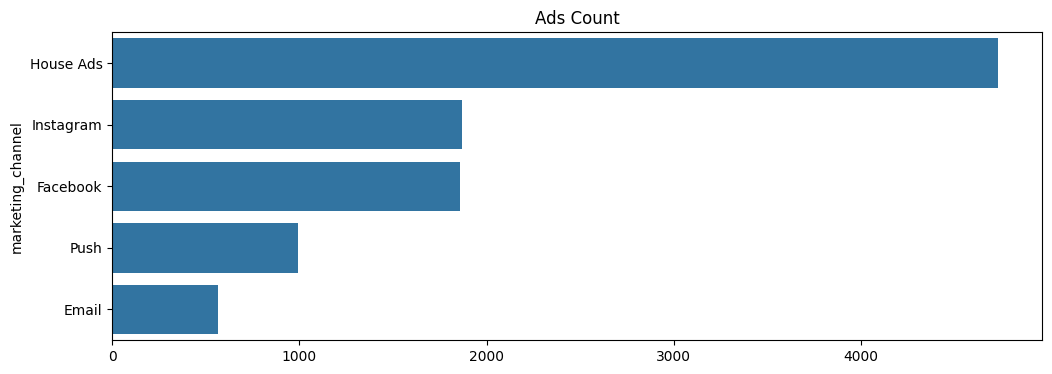

In [24]:
# Bar chart of total ads served per channel
plt.figure(figsize=(12,4))
ax = sns.countplot(df['marketing_channel'], order=channel_count.index)
plt.xlabel("")
plt.title("Ads Count", fontsize=12);

In [25]:
# Daily ad count per channel (rows = dates, columns = channels)
daily_ads_count = df.pivot_table(values="user_id",index="date_served", columns="marketing_channel", aggfunc=len)
daily_ads_count.head(10)

marketing_channel,Email,Facebook,House Ads,Instagram,Push
date_served,,,,,
2018-01-01,1,69,191,78,36
2018-01-02,4,64,250,63,36
2018-01-03,2,63,220,66,37
2018-01-04,2,66,168,64,36
2018-01-05,1,64,160,70,36
2018-01-06,5,64,152,65,29
2018-01-07,3,52,132,60,34
2018-01-08,1,67,154,65,32
2018-01-09,2,59,157,60,37


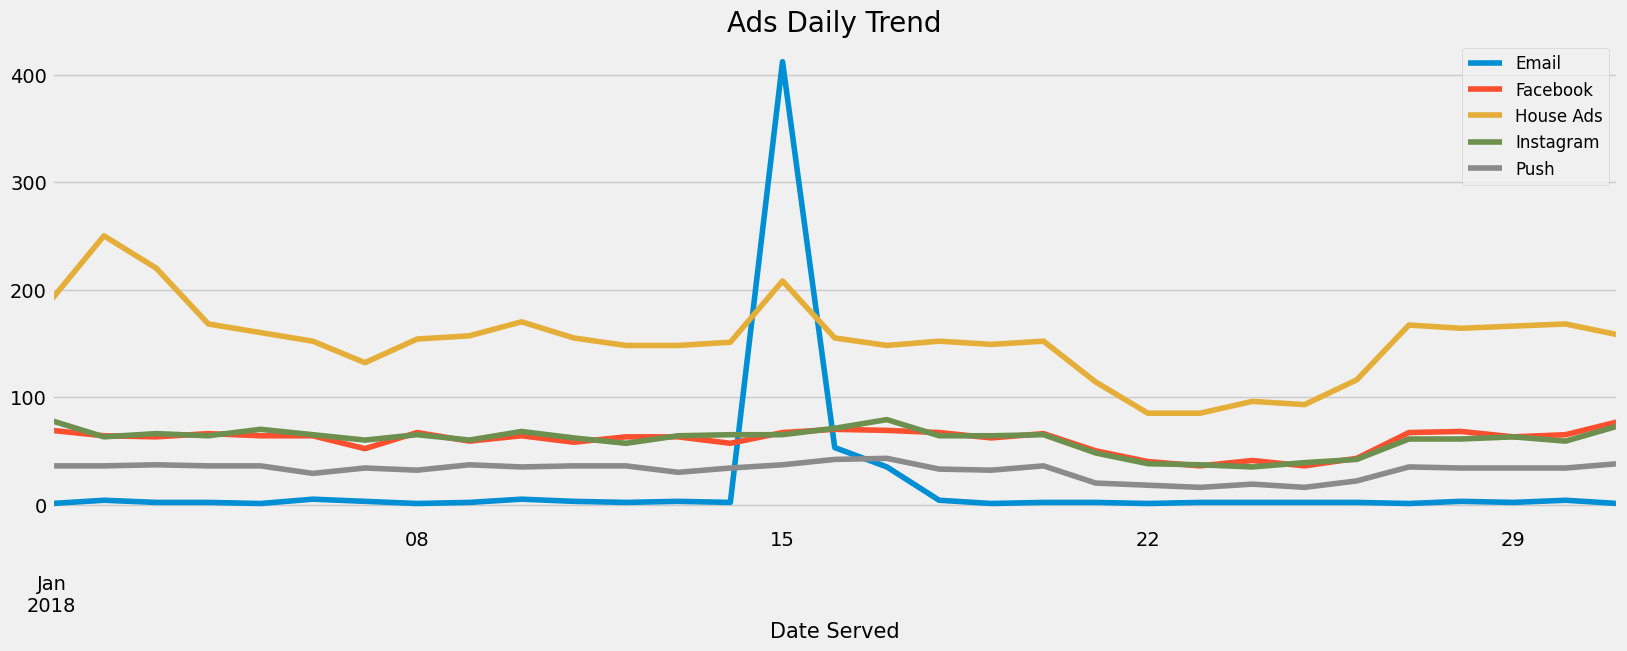

In [34]:
# Line chart of the daily ad volume by channel
plt.style.use('fivethirtyeight')
daily_ads_count.plot(kind='line',figsize=(18,6))
plt.xlabel("Date Served",size=15);
plt.title("Ads Daily Trend",size=20)
plt.legend(loc='upper right',fontsize=12);

**Observations**
- **Email** is almost negligible on a normal day (1–5 ads) except for a single **email blast on 15 January** (about 410 emails).
- **House Ads** are the largest channel but fluctuate the most, with visible dips around 7–8 Jan and 21–26 Jan.
- **Facebook, Instagram and Push** are stable for most of the month, with a common dip around 21–26 January.

### 4.3 Conversion Rate by Marketing Channel

In [ ]:
# Total conversions and total ads served per channel
# (sum of 'converted' = conversions, count of 'converted' = ads with a known outcome)
conversions = df.groupby('marketing_channel')['converted'].sum()
ads = df.groupby('marketing_channel')['converted'].count()
conversion_df = pd.concat([conversions, ads], axis=1)
# Give the columns descriptive names
conversion_df.columns=['conversions','ads_served']
conversion_df

,conversions,ads_served
marketing_channel,,
Email,193.0,565
Facebook,237.0,1860
House Ads,298.0,4733
Instagram,265.0,1871
Push,83.0,993


In [39]:
# Conversion rate = conversions / ads served
conversion_df['conversion_rate'] = conversion_df['conversions']/conversion_df['ads_served']
conversion_df

,conversions,ads_served,conversion_rate
marketing_channel,,,
Email,193.0,565,0.341593
Facebook,237.0,1860,0.127419
House Ads,298.0,4733,0.062962
Instagram,265.0,1871,0.141635
Push,83.0,993,0.083585


**Conclusions**
- **Email has by far the highest conversion rate (34.2%)**, followed by Instagram (14.2%), Facebook (12.7%) and Push (8.4%).
- **House Ads have the lowest rate (6.3%)** although they receive the largest share of ads. Why the budget is allocated mostly to the lowest-converting channel needs to be reviewed.

### 4.4 Control vs. Personalization Groups

In [47]:
# Conversions and ads served per variant and channel
conversions = df.groupby(['variant','marketing_channel'])['converted'].sum()
ads = df.groupby(['variant','marketing_channel'])['converted'].count()
conversion_df = pd.concat([conversions,ads],axis=1)
conversion_df

converted  converted
variant         marketing_channel                      
control         Email                   80.0        274
                Facebook                52.0        894
                House Ads              172.0       2552
                Instagram               52.0        888
                Push                    15.0        468
personalization Email                  113.0        291
                Facebook               185.0        966
                House Ads              126.0       2181
                Instagram              213.0        983
                Push                    68.0        525

In [48]:
# Give the columns descriptive names and calculate conversion rates (rounded to 2 decimals)
conversion_df.columns=['conversions','ads_served']
conversion_df['conversion_rate'] = round(conversion_df['conversions']/conversion_df['ads_served'], 2)
conversion_df

conversions  ads_served  conversion_rate
variant         marketing_channel                                          
control         Email                     80.0         274             0.29
                Facebook                  52.0         894             0.06
                House Ads                172.0        2552             0.07
                Instagram                 52.0         888             0.06
                Push                      15.0         468             0.03
personalization Email                    113.0         291             0.39
                Facebook                 185.0         966             0.19
                House Ads                126.0        2181             0.06
                Instagram                213.0         983             0.22
                Push                      68.0         525             0.13

In [55]:
# Total conversions and total ads served per variant
# (control has 15 fewer ads here because records with a missing outcome are not counted)
print(conversion_df['conversions'].groupby(level=0).sum())

print(conversion_df['ads_served'].groupby(level=0).sum())

variant
control            371.0
personalization    705.0
Name: conversions, dtype: float64
variant
control            5076
personalization    4946
Name: ads_served, dtype: int64


**Conclusions**
- The personalization group produced **705 conversions vs. 371 in the control group** on a comparable number of ads (4,946 vs. 5,076).
- The ad distribution by channel was almost identical in both groups (first chart), so the comparison is fair.
- Personalization improved conversion on **Email (0.29 to 0.39), Facebook (0.06 to 0.19), Instagram (0.06 to 0.22) and Push (0.03 to 0.13)**. For **House Ads** there was almost no gain (0.07 vs. 0.06).

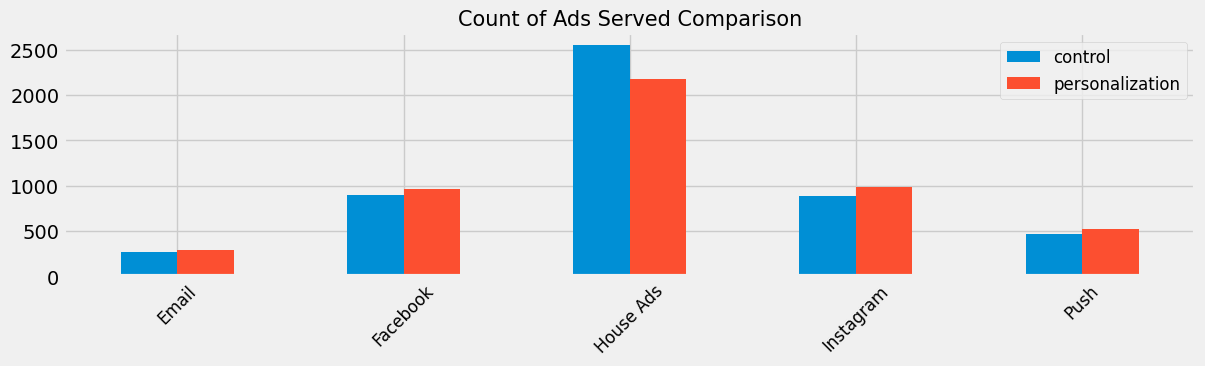

In [56]:
# Ads served per channel: control vs. personalization (checks that the groups are balanced)
plt.style.use('fivethirtyeight')

conversion_df.unstack(level=0).plot(kind='bar', y='ads_served', figsize=(13,3))

plt.title("Count of Ads Served Comparison", size=15)
plt.xlabel("")
plt.xticks(rotation=45, size=12)
plt.legend(loc='upper right', fontsize=12);

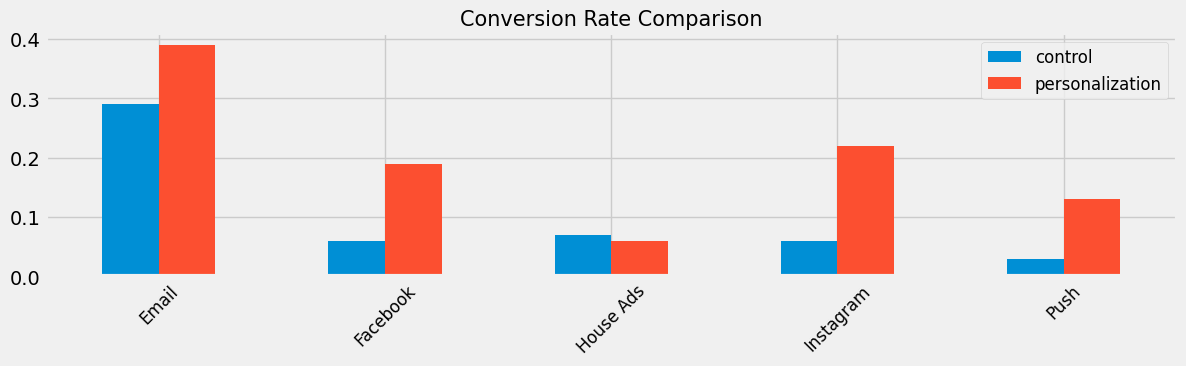

In [58]:
# Conversion rate per channel: control vs. personalization
plt.style.use('fivethirtyeight')

conversion_df.unstack(level=0).plot(kind='bar', y='conversion_rate',figsize=(13,3))

plt.title("Conversion Rate Comparison",size=15)
plt.xlabel("")
plt.xticks(rotation=45, size=12)
plt.legend(loc='upper right',fontsize=12);

<a id="retention"></a>
## 5. Retention Rate

In [61]:
# Keep only users who converted (subscribed)
converted_df = df[df['converted'] == 1]
converted_df.head()

,user_id,date_served,marketing_channel,variant,converted,language_displayed,language_preferred,age_group,date_subscribed,date_canceled,subscribing_channel,is_retained,DOW_subscribed,is_language_correct
0,a100000029,2018-01-01,House Ads,personalization,1.0,English,English,0-18,2018-01-01,NaT,House Ads,1.0,Mon,True
1,a100000030,2018-01-01,House Ads,personalization,1.0,English,English,19-24,2018-01-01,NaT,House Ads,1.0,Mon,True
2,a100000031,2018-01-01,House Ads,personalization,1.0,English,English,24-30,2018-01-01,NaT,House Ads,1.0,Mon,True
3,a100000032,2018-01-01,House Ads,personalization,1.0,English,English,30-36,2018-01-01,NaT,House Ads,1.0,Mon,True
4,a100000033,2018-01-01,House Ads,personalization,1.0,English,English,36-45,2018-01-01,NaT,House Ads,1.0,Mon,True


In [ ]:
# Retention rate = share of converted users who are still subscribed
total_subs = converted_df['user_id'].nunique()
retained_subs = converted_df.loc[converted_df['is_retained'] == 1]['user_id'].nunique()
print("Retention Rate: {}%".format(100*round(retained_subs/total_subs, 3)))

Retention Rate: 64.5%


**Conclusion:** About **64,5% of subscribers are retained**, so roughly 4 in 10 subscribers cancel within the observed period.

<a id="segments"></a>
## 6. Conversion Analysis by Age Group, Channel and Day of Week

### 6.1 Conversion by Age Group

In [67]:
# Number of ads by channel, conversion outcome (0/1) and age group
age_df = df.pivot_table(values='user_id',index=['marketing_channel','converted'], columns='age_group', aggfunc=len)
age_df

age_group                    0-18  19-24  24-30  30-36  36-45  45-55  55+
marketing_channel converted                                              
Email             0.0          54     59     68     47     51     50   43
                  1.0          39     52     52     13     12     15   10
Facebook          0.0         215    269    247    228    213    290  161
                  1.0          49     78     49     21     13      9   18
House Ads         0.0         636    703    623    668    558    647  600
                  1.0          58     58     58     31     31     31   31
Instagram         0.0         261    214    230    246    261    207  187
                  1.0          39    101     56     13     19     20   17
Push              0.0         170    120    160     82    190     77  111
                  1.0          16     25     23      4      3      5    7

**Helper function: conversion rate**

Calculates the share of unique users who converted for any grouping of columns.

In [72]:
# Reusable helper: conversion rate = unique converted users / unique users within each group
def conversion_rate(df, column_names):
    # Total number of converted users
    column_conv = df[df['converted'] == 1].groupby(column_names)['user_id'].nunique()

    # Total number users
    column_total = df.groupby(column_names)['user_id'].nunique()  
    
    # Conversion rate 
    conversion_rate = round(column_conv/column_total, 2)
    
    # Fill missing values with 0
    conversion_rate = conversion_rate.fillna(0)
    return conversion_rate

In [71]:
# Conversion rate for each channel and age group combination
age_group_conrate = conversion_rate(df,["marketing_channel","age_group"])
age_group_conrate

marketing_channel  age_group
Email              0-18         0.41
                   19-24        0.46
                   24-30        0.45
                   30-36        0.22
                   36-45        0.19
                   45-55        0.22
                   55+          0.19
Facebook           0-18         0.17
                   19-24        0.23
                   24-30        0.17
                   30-36        0.07
                   36-45        0.06
                   45-55        0.03
                   55+          0.09
House Ads          0-18         0.10
                   19-24        0.09
                   24-30        0.10
                   30-36        0.05
                   36-45        0.06
                   45-55        0.05
                   55+          0.06
Instagram          0-18         0.13
                   19-24        0.31
                   24-30        0.19
                   30-36        0.05
                   36-45        0.06
         

In [74]:
# Reshape: age groups as rows, channels as columns (convenient for plotting)
age_group_conv_df = pd.DataFrame(age_group_conrate.unstack(level=0))
age_group_conv_df

marketing_channel,Email,Facebook,House Ads,Instagram,Push
age_group,,,,,
0-18,0.41,0.17,0.10,0.13,0.08
19-24,0.46,0.23,0.09,0.31,0.17
24-30,0.45,0.17,0.10,0.19,0.11
30-36,0.22,0.07,0.05,0.05,0.05
36-45,0.19,0.06,0.06,0.06,0.02
45-55,0.22,0.03,0.05,0.07,0.06
55+,0.19,0.09,0.06,0.07,0.05


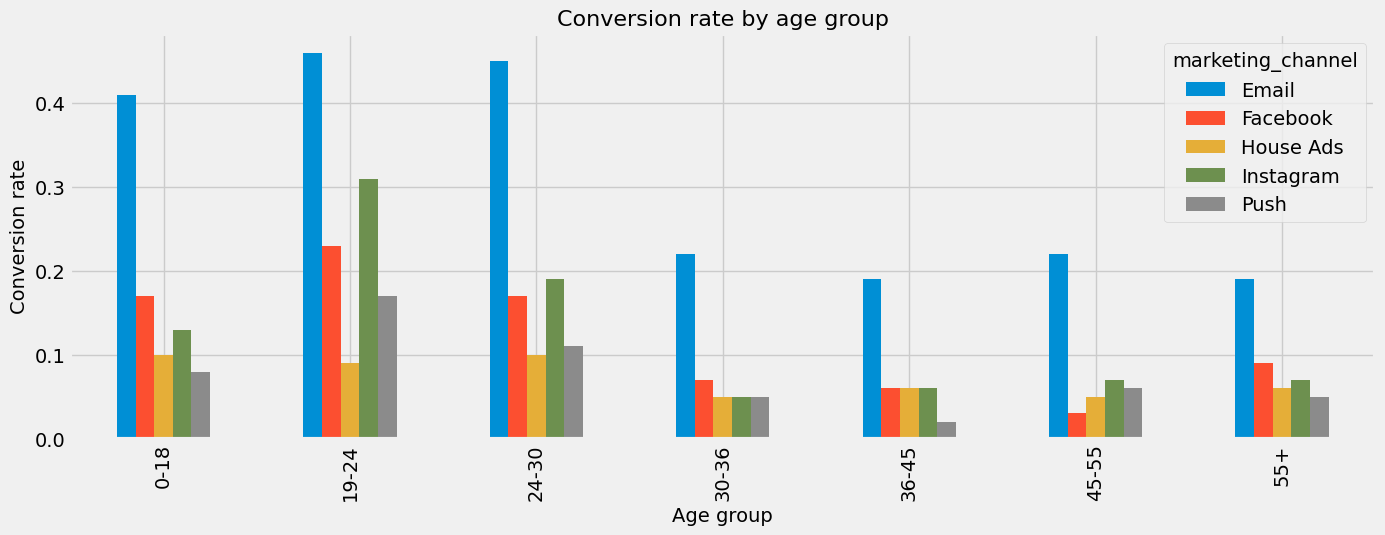

In [76]:
# Bar chart of the conversion rate by age group and channel
plt.style.use('fivethirtyeight')
age_group_conv_df.plot(kind = 'bar',figsize=(15,5))


plt.title('Conversion rate by age group', size = 16)
plt.ylabel('Conversion rate', size = 14)
plt.xlabel('Age group', size = 14);

**Conclusions**
- **Users aged up to 30 convert far better** than users aged 30 and above on every channel. For example, Email reaches 41–46% for ages 0–30 but only 19–22% for older groups, and Instagram peaks at 31% for ages 19–24.
- The **19–24 group is the best segment** on almost every channel.
- **House Ads convert poorly even among young users** (9–10%), well below Email, Instagram and Facebook for the same groups.

### 6.2 Conversion by Channel over Time

In [ ]:
# Daily conversion rate per channel (rows = dates, columns = channels)
channel_convr_df = pd.DataFrame(conversion_rate(df,['date_served','marketing_channel']).unstack(level=1))
channel_convr_df.head(10)

marketing_channel,Email,Facebook,House Ads,Instagram,Push
date_served,,,,,
2018-01-01,1.0,0.12,0.08,0.11,0.08
2018-01-02,1.0,0.10,0.08,0.13,0.06
2018-01-03,0.0,0.08,0.09,0.17,0.08
2018-01-04,0.5,0.14,0.09,0.13,0.06
2018-01-05,1.0,0.11,0.13,0.16,0.03
2018-01-06,0.6,0.11,0.11,0.10,0.07
2018-01-07,1.0,0.10,0.15,0.18,0.09
2018-01-08,1.0,0.14,0.10,0.12,0.06
2018-01-09,0.5,0.12,0.13,0.15,0.05


In [78]:
# Helper: draw one plot per column of a conversion-rate table
def plotting_conv(df,kind):
    for column in df.columns:
        plt.style.use('ggplot')
        df[column].plot(kind=kind,figsize=(20,5))
        
        plt.title(column + ' conversion rate', size = 16)
        plt.ylabel('Conversion rate', size = 14)
        plt.grid(False)
        plt.show()
        plt.clf();

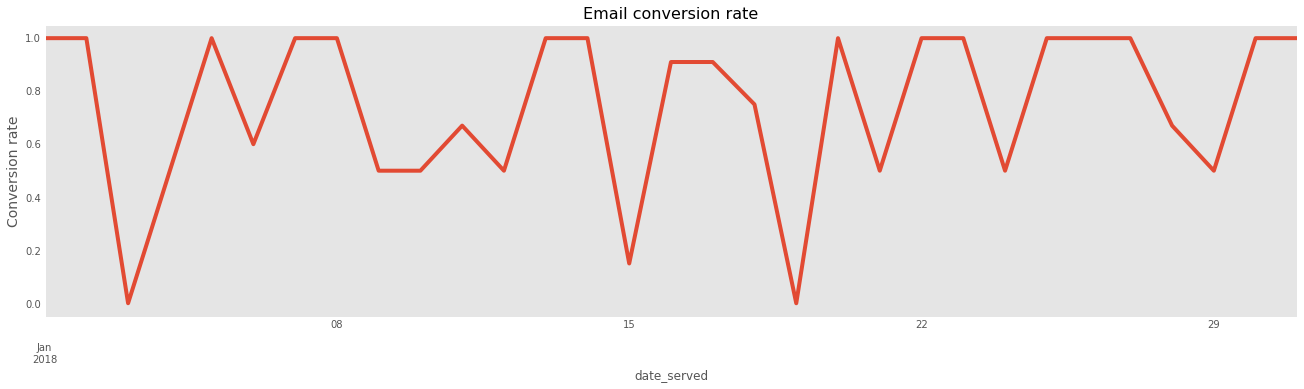

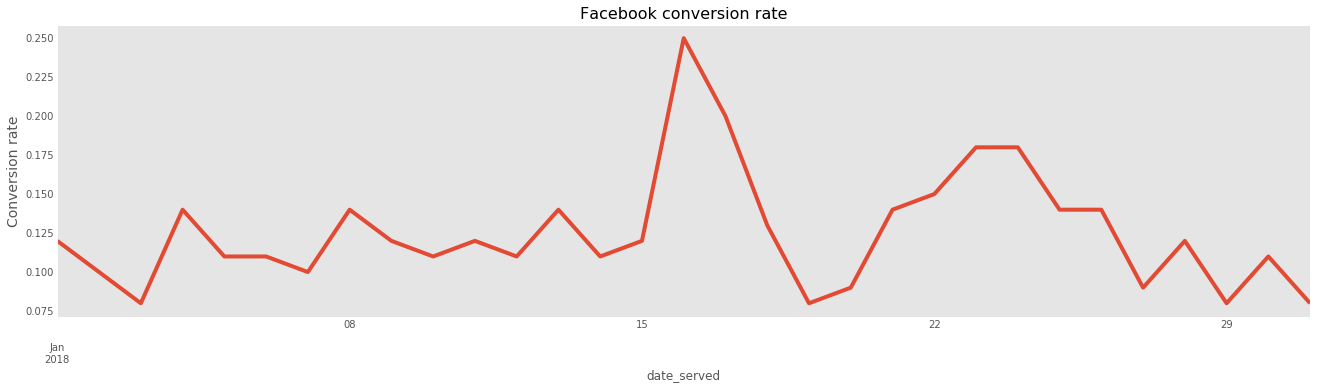

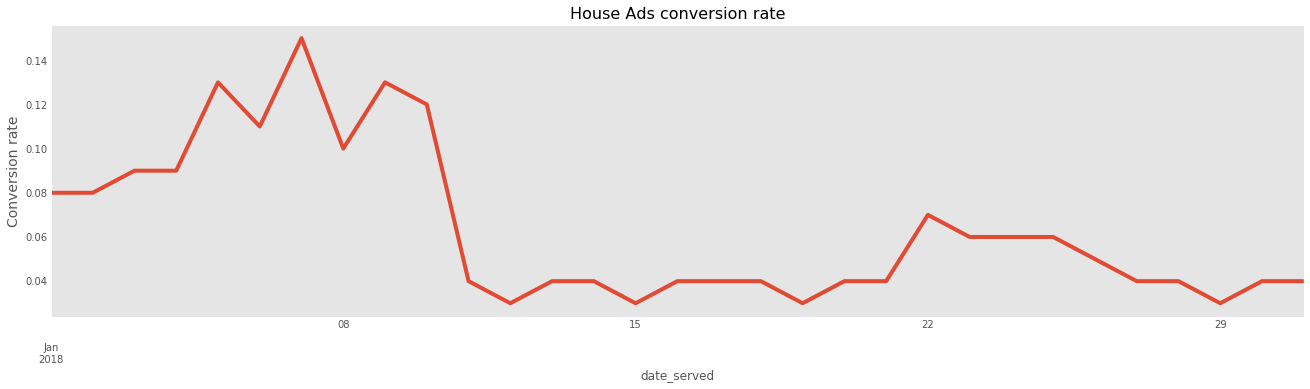

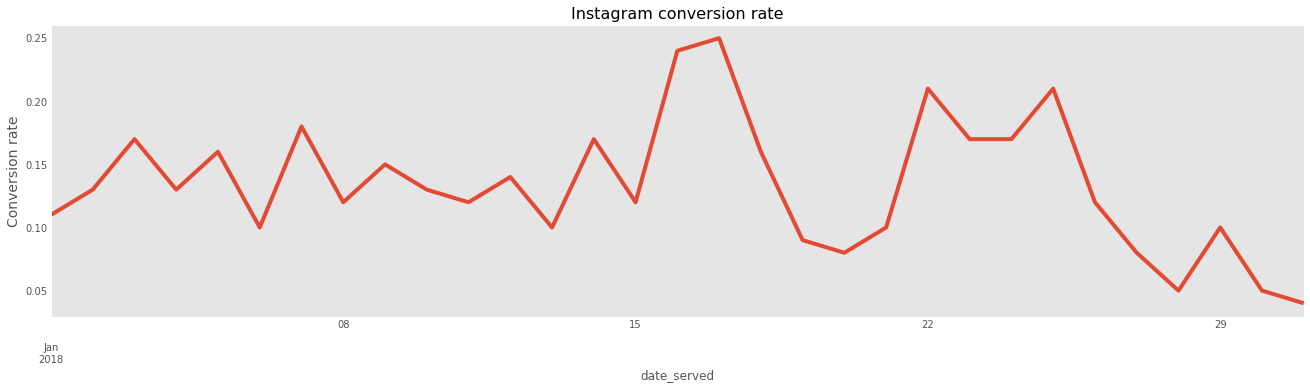

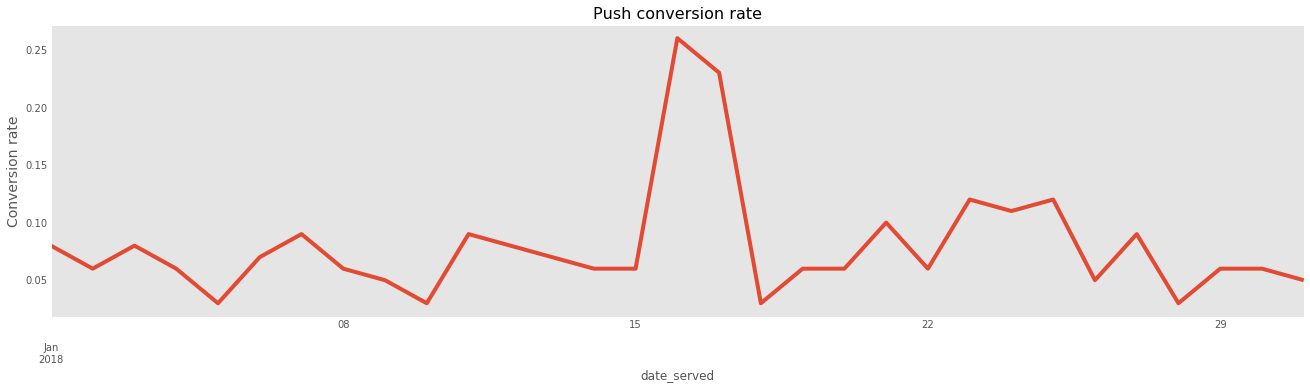

<Figure size 432x288 with 0 Axes>

In [ ]:
# Daily conversion rate trend, one chart per channel
plotting_conv(channel_convr_df,"line");

**Conclusions**
- **Email** has very high and volatile daily rates because only 1–5 emails are sent on most days, so small numbers swing the rate between 0% and 100%.
- Facebook, Instagram and Push fluctuate from day to day without a clear trend.
- **House Ads conversion fell sharply from 11 January** (from roughly 8–14% to about 3–4%) and never fully recovered. This is investigated in Section 7.

### 6.3 Conversion by Age Group over Time

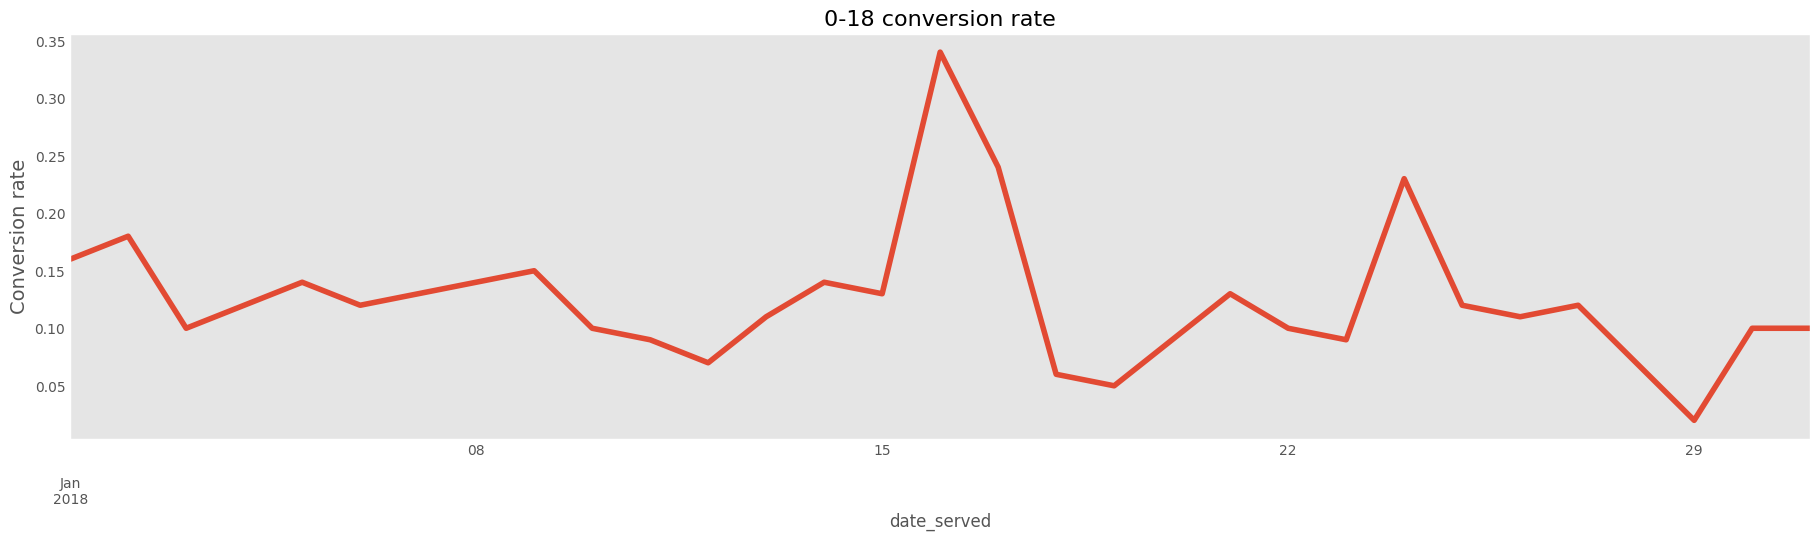

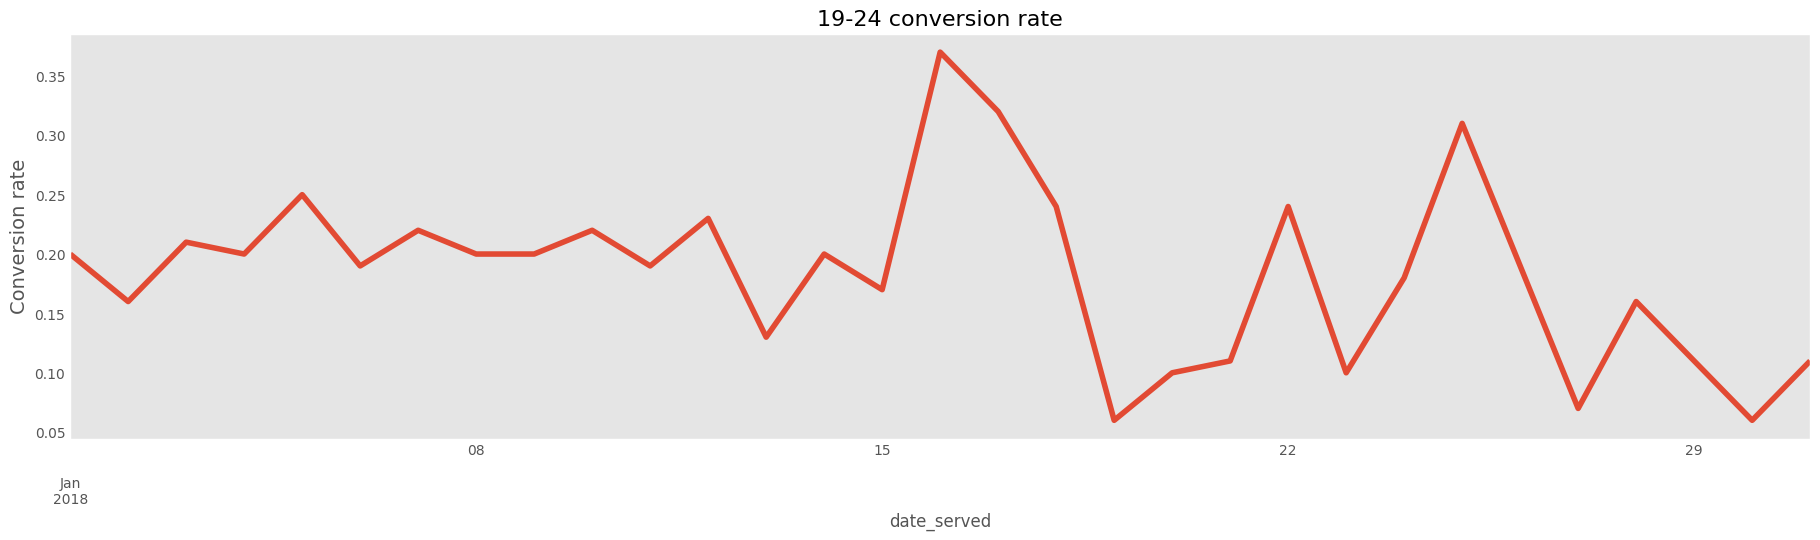

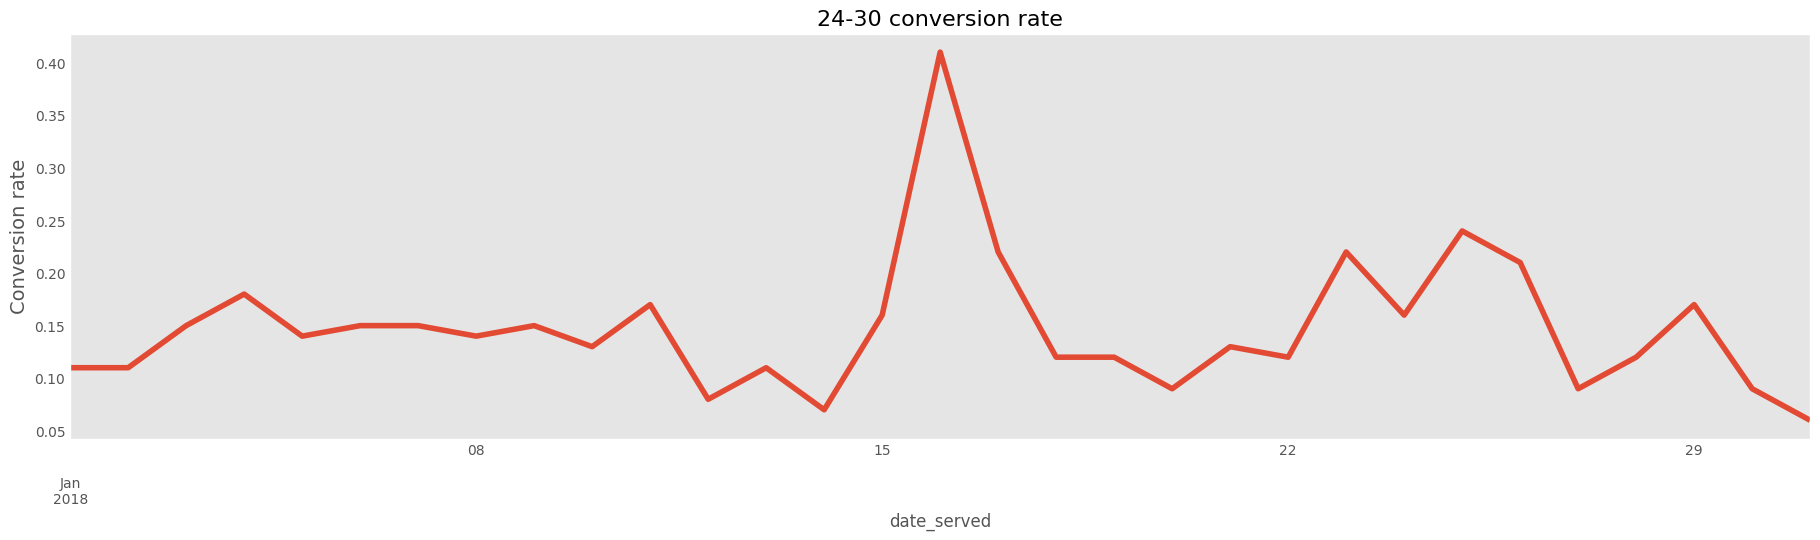

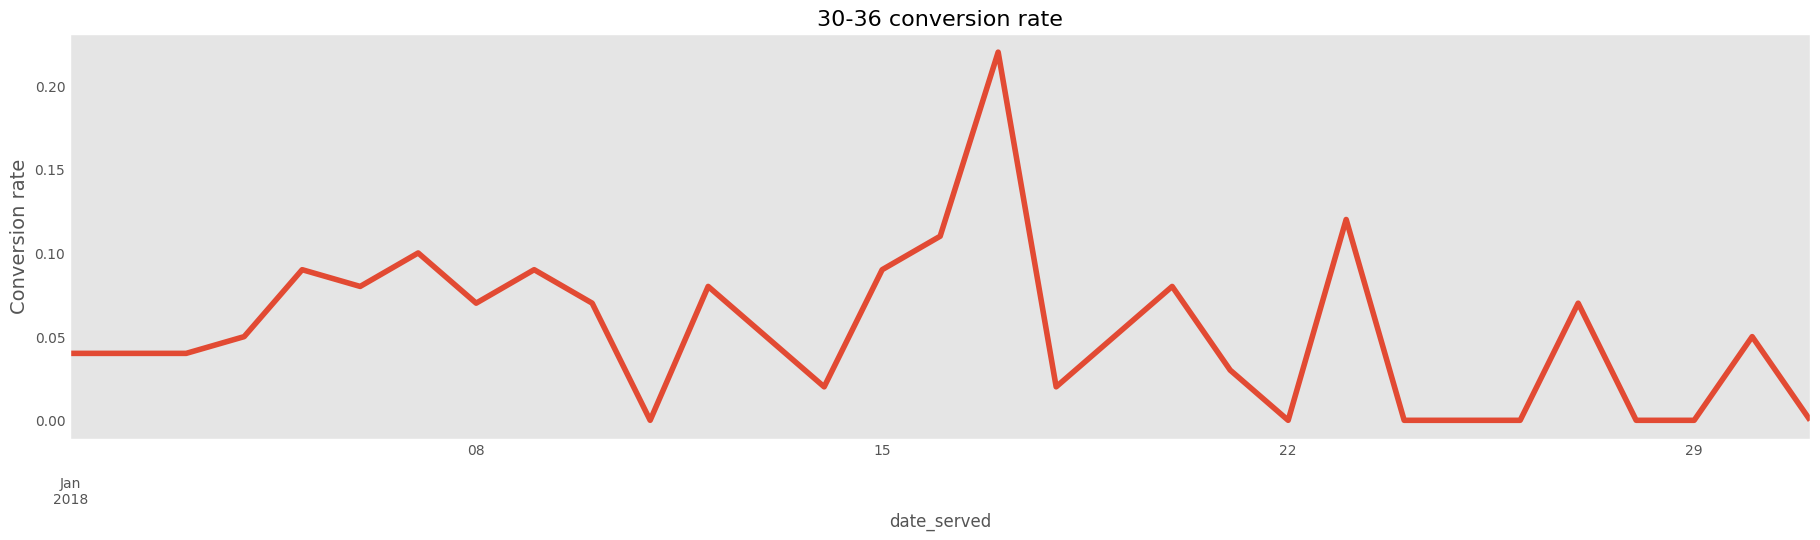

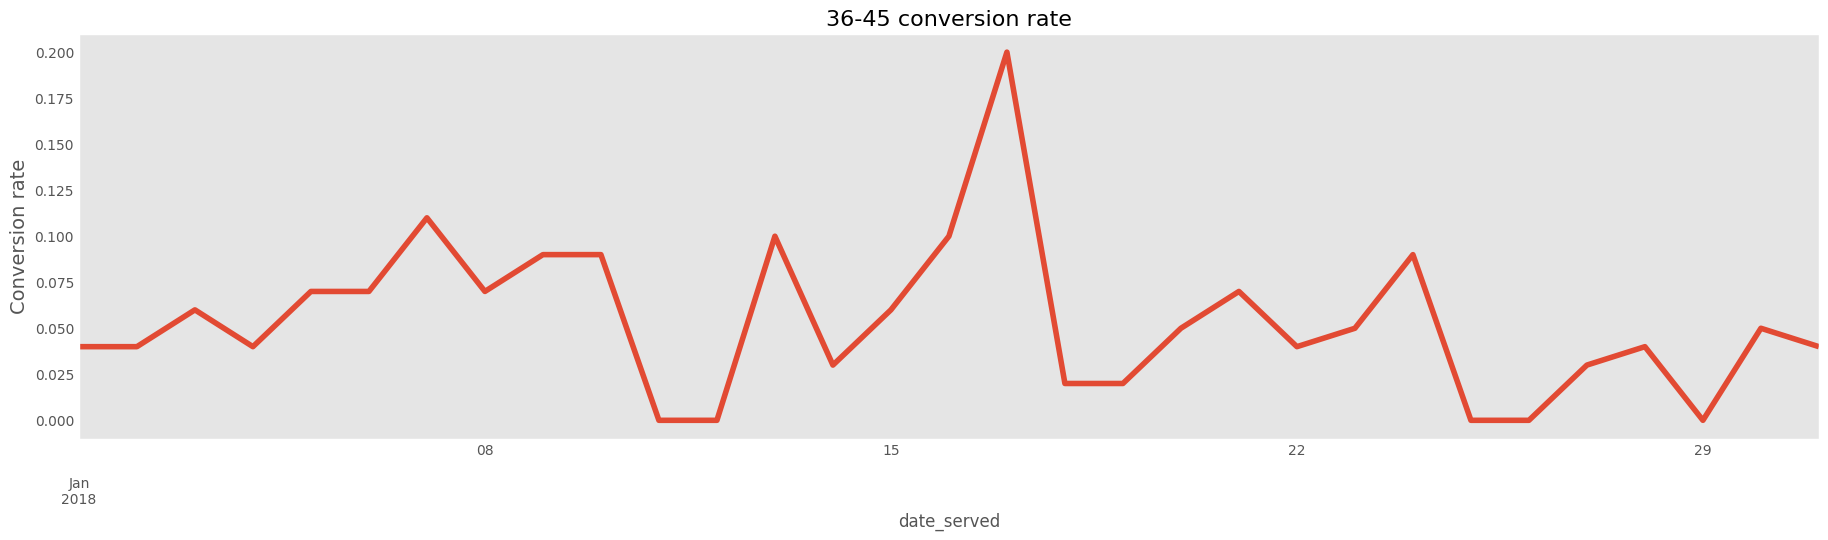

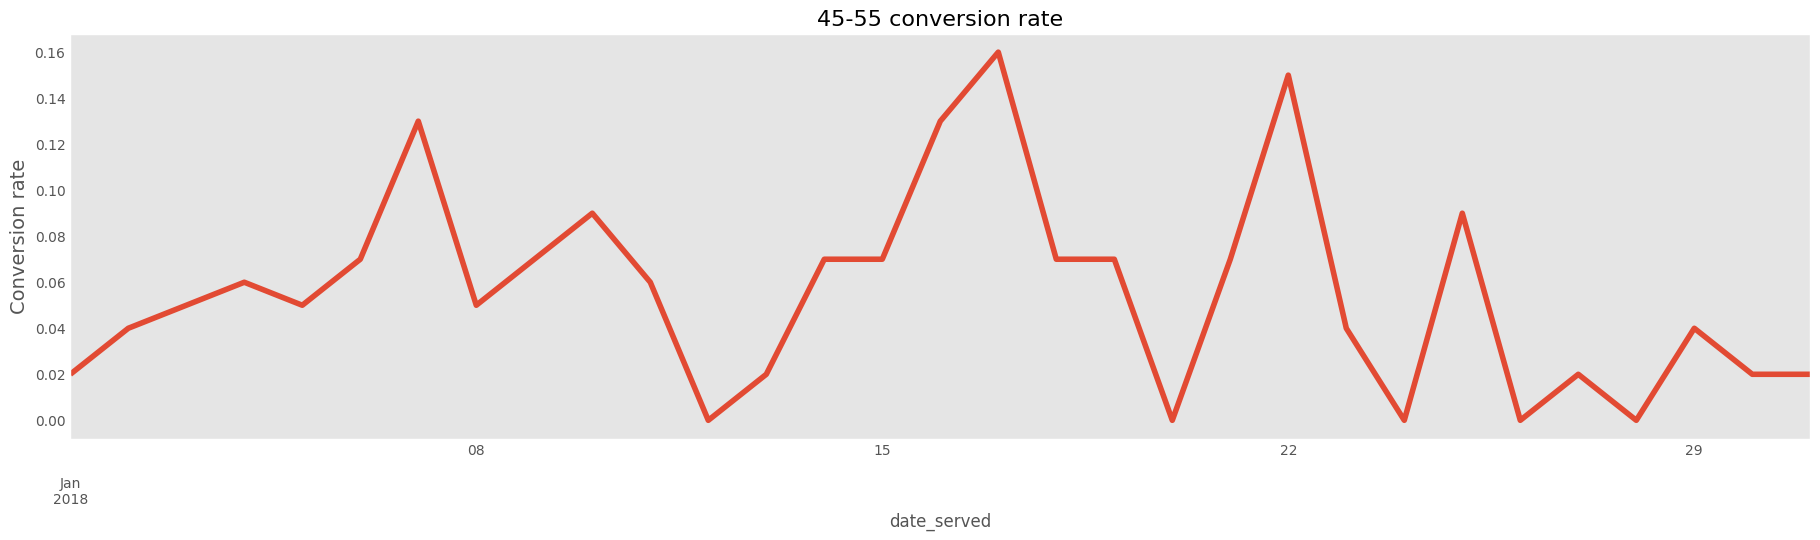

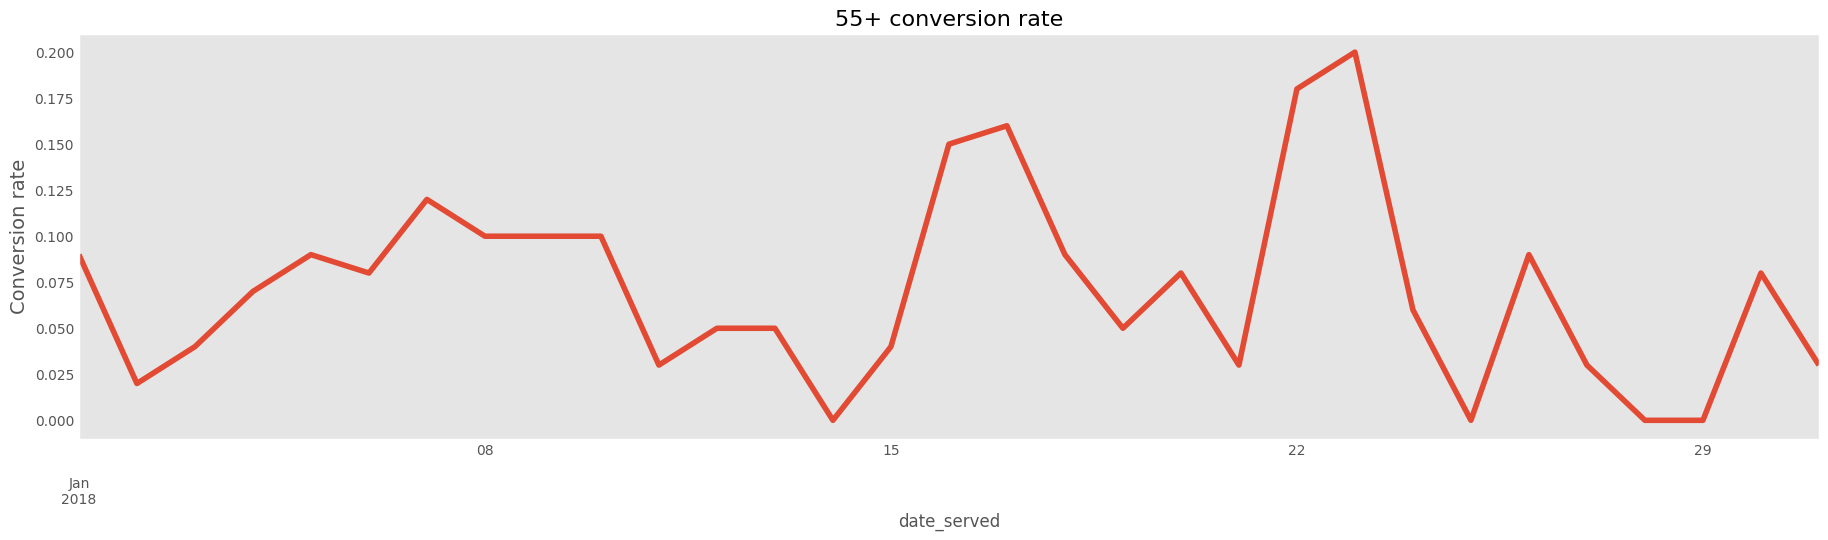

<Figure size 640x480 with 0 Axes>

In [79]:
# Daily conversion rate trend, one chart per age group
age_group_conv_df = pd.DataFrame(conversion_rate(df,['date_served','age_group']).unstack(level=1))
plotting_conv(age_group_conv_df,"line")

**Conclusions**
- Every age group shows a **spike in conversion around 16 January**, shortly after the 15 January email blast.
- The spike coincides with higher conversion on the Facebook, Instagram and Push channels over the same days, so it is most likely a campaign-wide effect.

### 6.4 Conversion by Day of the Week

In [88]:
# Day of week on which the ad was served (0 = Monday ... 6 = Sunday)
df['DOW_served'] = df['date_served'].dt.dayofweek

In [89]:
# Conversion rate by day of week and channel
DOW_conversion_df = pd.DataFrame(conversion_rate(df,['DOW_served','marketing_channel']).unstack(level=1))
DOW_conversion_df

marketing_channel,Email,Facebook,House Ads,Instagram,Push
DOW_served,,,,,
0.0,0.16,0.12,0.06,0.12,0.06
1.0,0.91,0.15,0.07,0.15,0.12
2.0,0.84,0.13,0.08,0.15,0.11
3.0,0.73,0.13,0.06,0.14,0.07
4.0,0.67,0.11,0.06,0.13,0.06
5.0,0.82,0.11,0.06,0.09,0.07
6.0,0.75,0.12,0.07,0.13,0.07


In [90]:
# Map day numbers to day names for readability
map_dict = {0.0: 'Mon', 1.0: 'Tue', 2.0: 'Wed', 3.0: 'Thu', 4.0: 'Fri',5.0: 'Sat',6.0: 'Sun'}
DOW_conversion_df['day'] = DOW_conversion_df.index.map(map_dict)
DOW_conversion_df

marketing_channel,Email,Facebook,House Ads,Instagram,Push,day
DOW_served,,,,,,
0.0,0.16,0.12,0.06,0.12,0.06,Mon
1.0,0.91,0.15,0.07,0.15,0.12,Tue
2.0,0.84,0.13,0.08,0.15,0.11,Wed
3.0,0.73,0.13,0.06,0.14,0.07,Thu
4.0,0.67,0.11,0.06,0.13,0.06,Fri
5.0,0.82,0.11,0.06,0.09,0.07,Sat
6.0,0.75,0.12,0.07,0.13,0.07,Sun


In [91]:
# Use the day names as the table index
DOW_conversion_df.set_index(DOW_conversion_df['day'], inplace=True)

In [92]:
# Drop the helper column
DOW_conversion_df.drop(columns='day', inplace=True)
DOW_conversion_df

marketing_channel,Email,Facebook,House Ads,Instagram,Push
day,,,,,
Mon,0.16,0.12,0.06,0.12,0.06
Tue,0.91,0.15,0.07,0.15,0.12
Wed,0.84,0.13,0.08,0.15,0.11
Thu,0.73,0.13,0.06,0.14,0.07
Fri,0.67,0.11,0.06,0.13,0.06
Sat,0.82,0.11,0.06,0.09,0.07
Sun,0.75,0.12,0.07,0.13,0.07


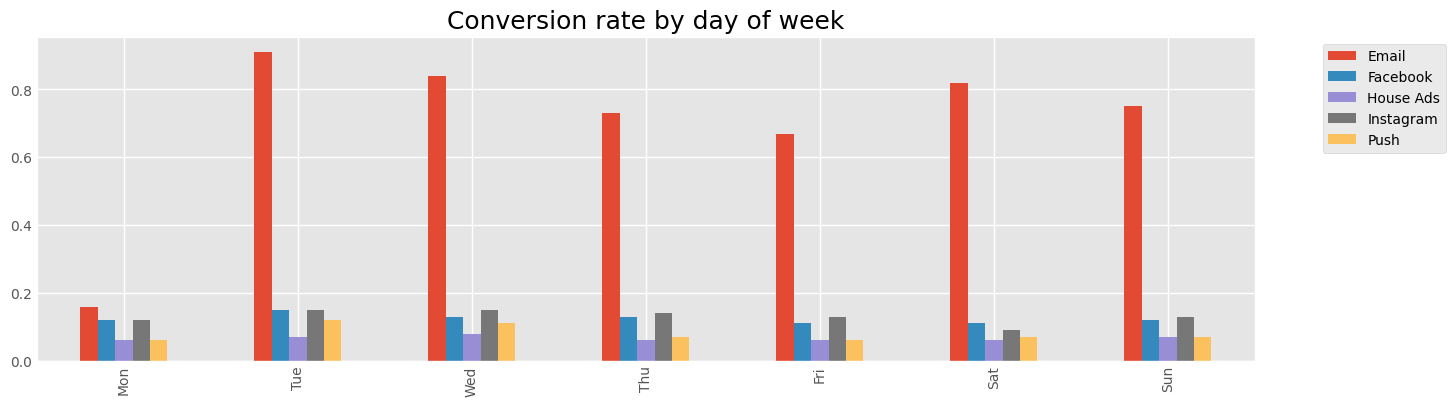

In [93]:
# Bar chart: conversion rate by day of week and channel
DOW_conversion_df.plot(kind="bar", figsize=(14,4))
plt.title('Conversion rate by day of week',fontsize=18)
plt.xlabel("")
plt.legend(bbox_to_anchor=(1.05, 1), loc=2);

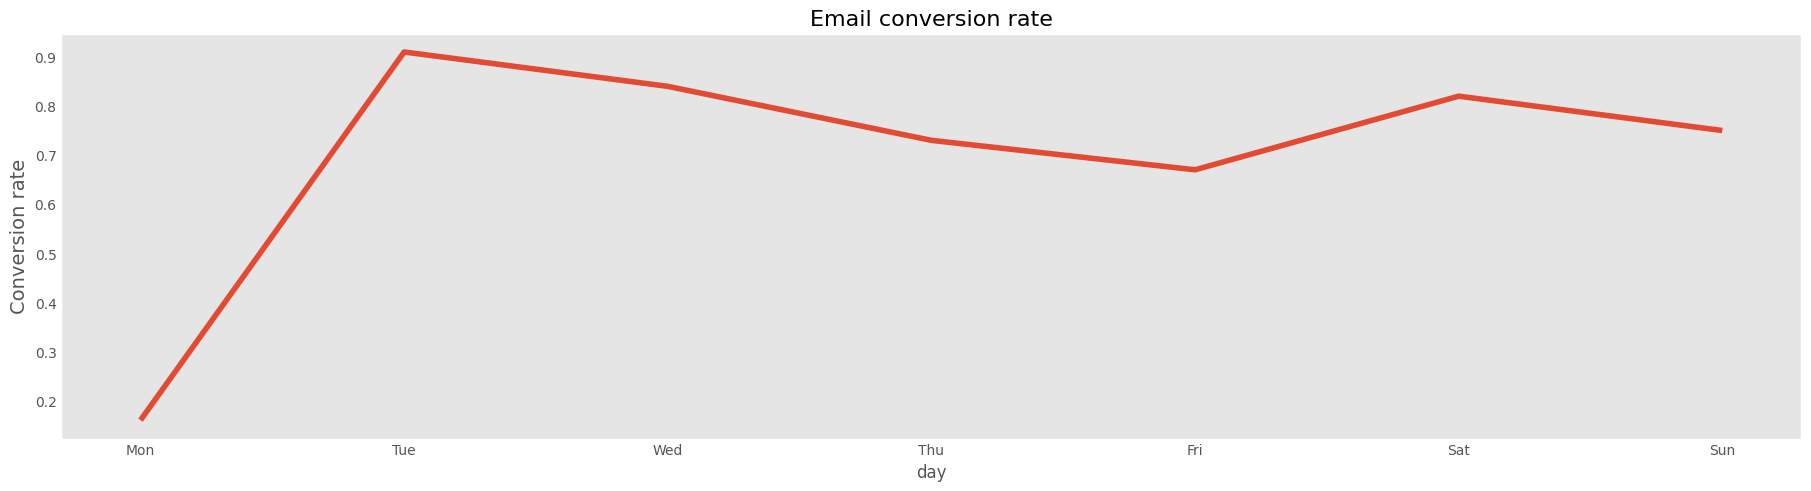

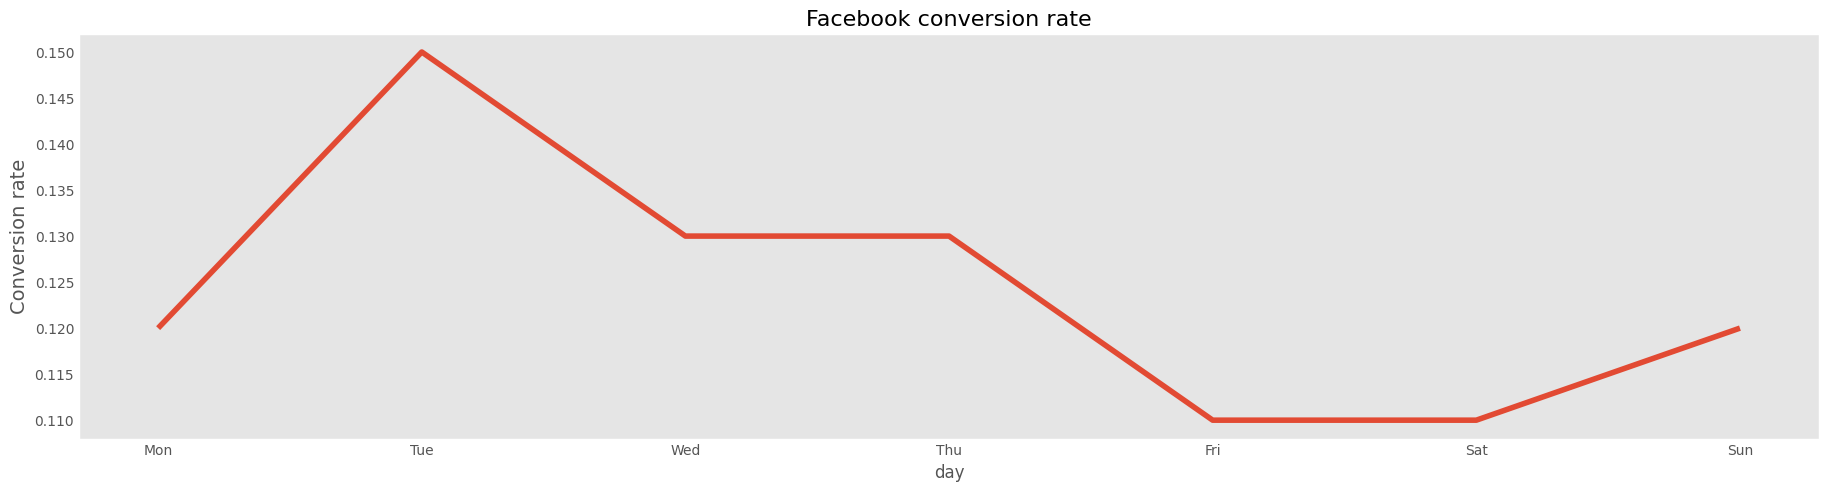

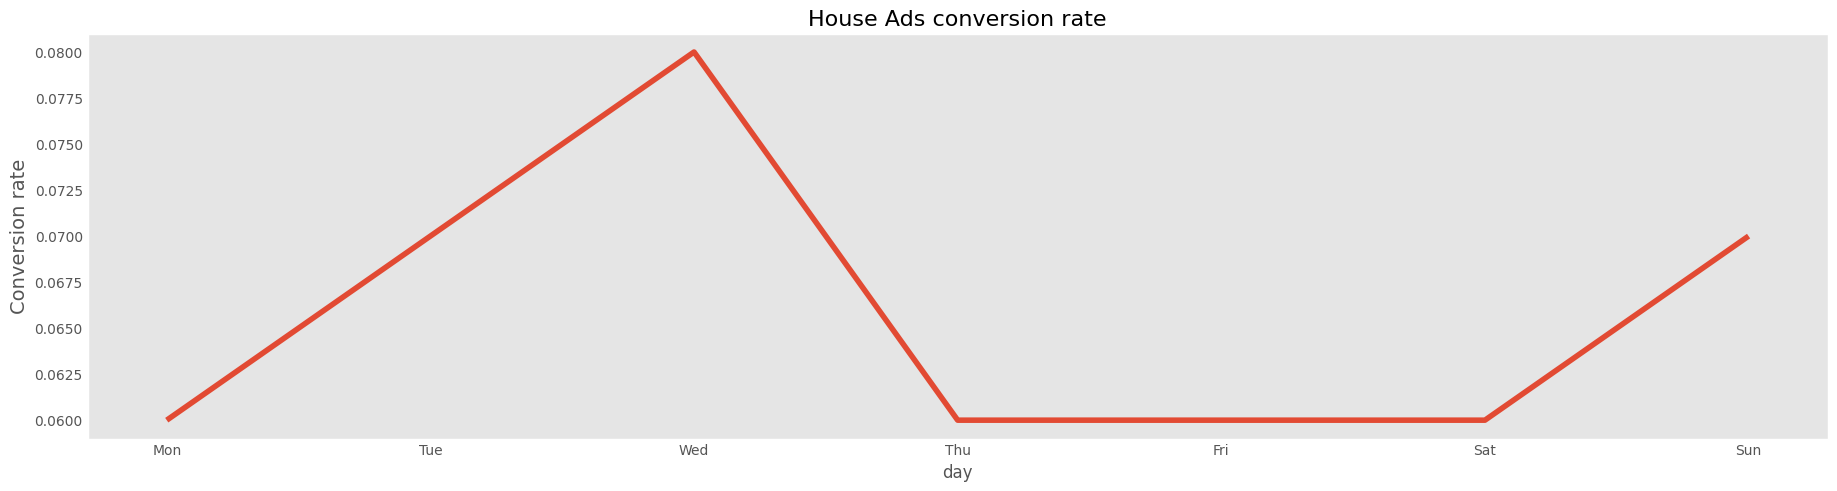

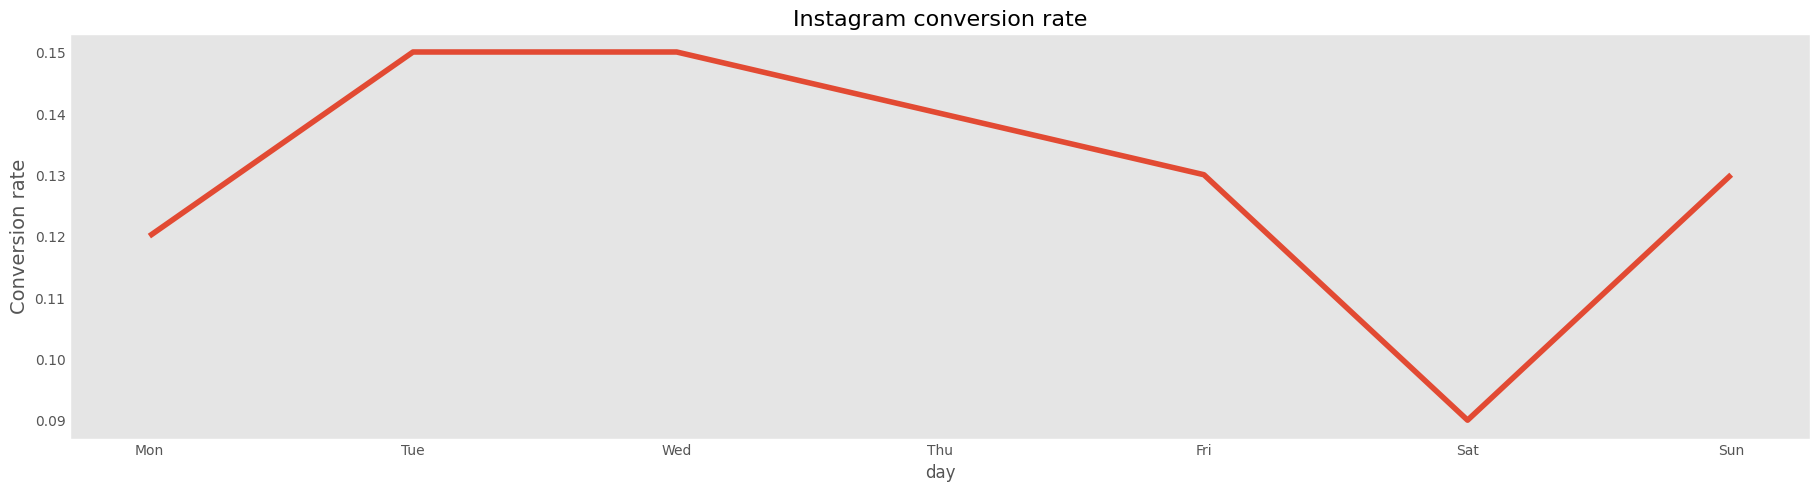

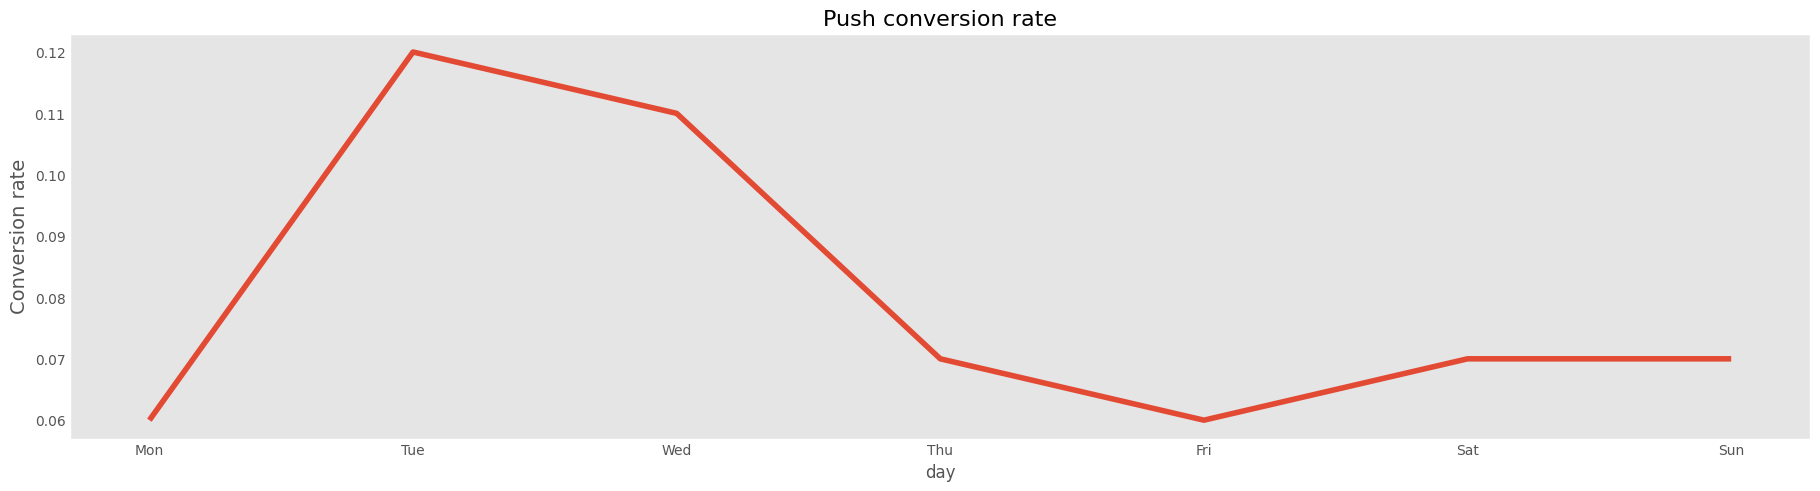

<Figure size 640x480 with 0 Axes>

In [94]:
# Line chart per channel of the conversion rate across the week
plotting_conv(DOW_conversion_df,"line");

**Conclusions**
- **A weekly pattern is visible on all five channels.** Conversion peaks on **Tuesday–Wednesday** (Email 0.91, Facebook 0.15, Instagram 0.15, Push 0.12 on Tuesday; House Ads 0.08 on Wednesday) and is weakest from **Friday to Monday** (Facebook 0.11, Instagram 0.09 on Saturday, Push 0.06 on Monday and Friday, House Ads 0.06).
- **The differences are small in absolute terms (2–6 percentage points) but large in relative terms.** Compared with the weakest day, the best day is about +36% for Facebook, +67% for Instagram, +33% for House Ads and 2x for Push. The charts use different y-axis scales, so each one visually exaggerates its own variation.
- **Email on Monday is the exception (16%, vs. 67–91% on other days).** This is consistent with the 15 January email blast (a Monday), which sent a large number of emails to a broad audience and diluted the rate.
- **Caveats.** Rates are rounded to two decimals, there are only about 140 (Push) to 680 (House Ads) ads per channel and weekday, and the differences were not tested statistically. The Tuesday peak may also be inflated by the conversion spike on 16 January (the day after the email blast; January 2018 has five Tuesdays), so the pattern should be re-checked without 15–17 January.
- Tuesday and Wednesday are also the best days for subscriptions overall (see Section 3.5), which supports the pattern. A practical next step is to concentrate campaign delivery on Tuesday–Wednesday and confirm the effect with a controlled test.

<a id="houseads"></a>
## 7. Deep Dive: House Ads Conversion Drop

**Business question.** The House Ads team noticed irregularities in the conversion rate. We need to decide whether this is a natural fluctuation (user behavior, day of week, time of month) or a real problem (technical implementation or marketing strategy).

### 7.1 Overall Trend

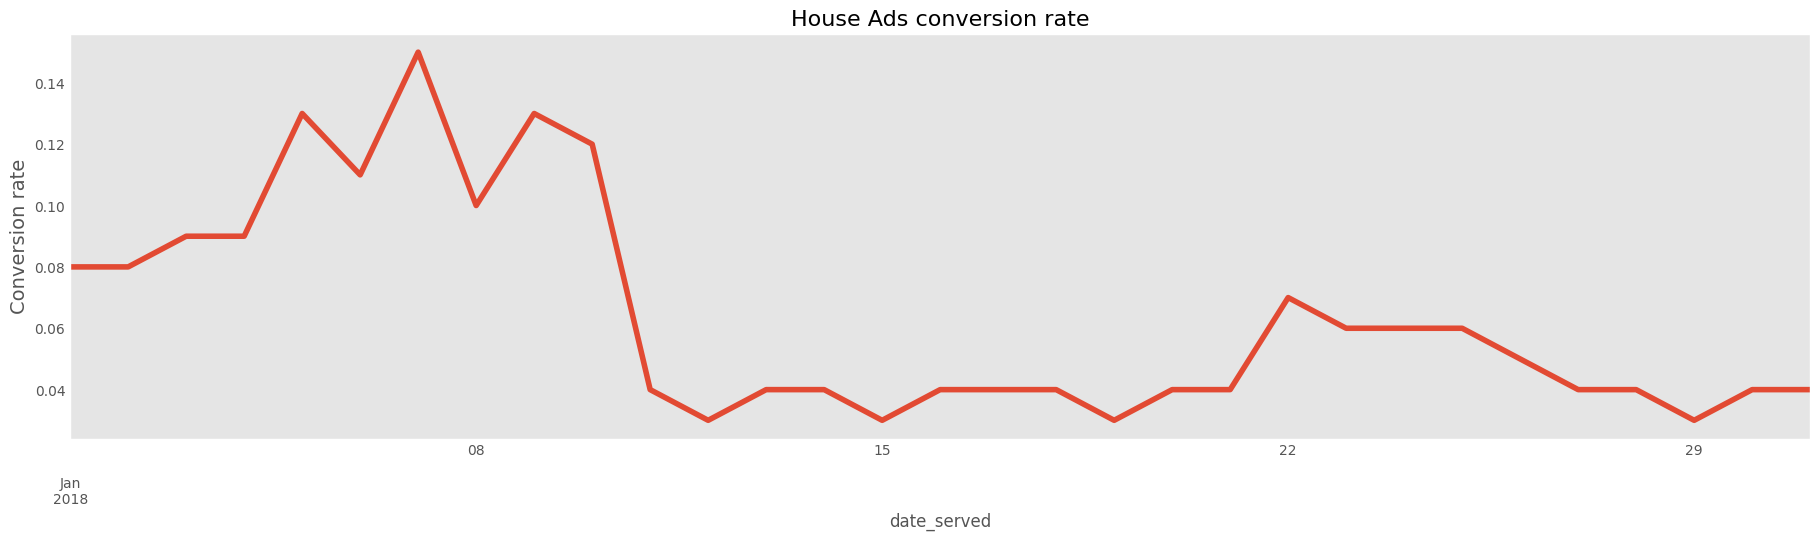

<Figure size 640x480 with 0 Axes>

In [95]:
# Daily conversion rate trend for House Ads
plotting_conv(pd.DataFrame(channel_convr_df['House Ads']),"line")

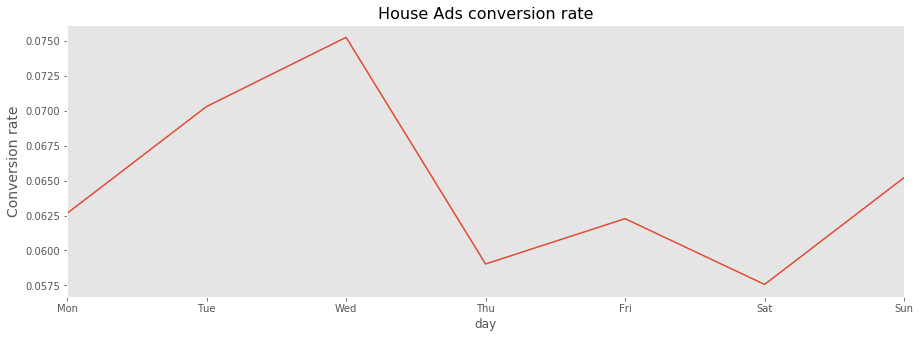

<Figure size 432x288 with 0 Axes>

In [ ]:
# House Ads conversion rate by day of week
plotting_conv(pd.DataFrame(DOW_conversion_df['House Ads']),"line")

**Observation.** House Ads conversion dropped from **11 January** (about 8–14% before, about 3–4% after). The next steps check whether this can be explained by user behavior or by a technical or marketing problem.

### 7.2 Control vs. Personalization

In [96]:
# Re-display the conversion table by variant and channel
conversion_df

conversions  ads_served  conversion_rate
variant         marketing_channel                                          
control         Email                     80.0         274             0.29
                Facebook                  52.0         894             0.06
                House Ads                172.0        2552             0.07
                Instagram                 52.0         888             0.06
                Push                      15.0         468             0.03
personalization Email                    113.0         291             0.39
                Facebook                 185.0         966             0.19
                House Ads                126.0        2181             0.06
                Instagram                213.0         983             0.22
                Push                      68.0         525             0.13

In [97]:
# Select only the House Ads rows (IndexSlice allows slicing on the second index level)
idx = pd.IndexSlice
conversion_df.loc[idx[:,'House Ads'],:]

,,conversions,ads_served,conversion_rate
variant,marketing_channel,,,
control,House Ads,172.0,2552,0.07
personalization,House Ads,126.0,2181,0.06


**Conclusion:** Control and personalization have almost the same low conversion rate for House Ads (0.07 vs. 0.06), so the drop is **not caused by the test variant**.

### 7.3 Weekday vs. Weekend

In [ ]:
# Prepare daily House Ads conversion rates and add the day of week
house_ads_df = pd.DataFrame(channel_convr_df["House Ads"])
house_ads_df.reset_index(inplace=True)
house_ads_df['DOW'] = house_ads_df['date_served'].dt.dayofweek
house_ads_df.head()

,date_served,House Ads,DOW
0,2018-01-01,0.08,0
1,2018-01-02,0.08,1
2,2018-01-03,0.09,2
3,2018-01-04,0.09,3
4,2018-01-05,0.13,4


In [99]:
# Label each date as Weekday (Mon-Fri) or Weekend (Sat-Sun)
house_ads_df['day type'] = house_ads_df['DOW'].apply(lambda x: "Weekday" if x<=4 else "Weekend")
house_ads_df.head(7)

,date_served,House Ads,DOW,day type
0,2018-01-01,0.08,0,Weekday
1,2018-01-02,0.08,1,Weekday
2,2018-01-03,0.09,2,Weekday
3,2018-01-04,0.09,3,Weekday
4,2018-01-05,0.13,4,Weekday
5,2018-01-06,0.11,5,Weekend
6,2018-01-07,0.15,6,Weekend


In [ ]:
# Average House Ads conversion rate on weekdays vs. weekends
print("Conversion rates for House Ads")
print(house_ads_df.groupby("day type")["House Ads"].mean())

Conversion rates for House Ads
day type
Weekday    0.064348
Weekend    0.062500
Name: House Ads, dtype: float64


**Conclusion:** Weekday (6.43%) and weekend (6.25%) conversion rates are practically identical, so the drop is **not a weekly seasonality effect**.

### 7.4 Ad Language vs. User Preferred Language

Since natural fluctuations are ruled out, the next hypothesis is that ads were shown in a language other than the one the user prefers.

In [ ]:
# Filter to House Ads and count ads shown in the correct vs. wrong language
house_ads_df = df[df['marketing_channel']=='House Ads']
print("Total house ads: {}".format(len(house_ads_df)))
print("House ads with wrong language: {}".format(sum(house_ads_df['language_displayed'] != house_ads_df['language_preferred'])))
print("House ads with correct language: {}".format(sum(house_ads_df['language_displayed'] == house_ads_df['language_preferred'])))
print("House ads conversions: {}".format(house_ads_df['converted'].sum()))

Total house ads: 4733
House ads with wrong language: 453
House ads with correct language: 4280
House ads conversions: 298.0


In [ ]:
# Add a Yes/No flag for language correctness
# (the SettingWithCopyWarning is harmless here; using .copy() when filtering would avoid it)
house_ads_df['is_language_correct'] = house_ads_df.apply(lambda x: "Yes" if x['language_displayed'] == x['language_preferred'] else "No", axis=1)
house_ads_df.head()

C:\Users\dzhur\AppData\Local\Temp\ipykernel_28620\2919270487.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  house_ads_df['is_language_correct'] = house_ads_df.apply(lambda x: "Yes" if x['language_displayed']==x['language_preferred'] else "No", axis=1)


,user_id,date_served,marketing_channel,variant,converted,language_displayed,language_preferred,age_group,date_subscribed,date_canceled,subscribing_channel,is_retained,DOW_subscribed,is_language_correct,DOW_served
0,a100000029,2018-01-01,House Ads,personalization,1.0,English,English,0-18,2018-01-01,NaT,House Ads,1.0,Mon,Yes,0.0
1,a100000030,2018-01-01,House Ads,personalization,1.0,English,English,19-24,2018-01-01,NaT,House Ads,1.0,Mon,Yes,0.0
2,a100000031,2018-01-01,House Ads,personalization,1.0,English,English,24-30,2018-01-01,NaT,House Ads,1.0,Mon,Yes,0.0
3,a100000032,2018-01-01,House Ads,personalization,1.0,English,English,30-36,2018-01-01,NaT,House Ads,1.0,Mon,Yes,0.0
4,a100000033,2018-01-01,House Ads,personalization,1.0,English,English,36-45,2018-01-01,NaT,House Ads,1.0,Mon,Yes,0.0


In [ ]:
# Daily count and percentage of House Ads shown in the correct language
house_ads_lang_df = house_ads_df.groupby(['date_served','is_language_correct'])['user_id'].count().unstack(level=1)
house_ads_lang_df.fillna(0, inplace=True)
house_ads_lang_df['Correct %'] = 100*house_ads_lang_df['Yes']/(house_ads_lang_df['No'] + house_ads_lang_df['Yes'])
house_ads_lang_df.round()

is_language_correct,No,Yes,Correct %
date_served,,,
2018-01-01,2.0,189.0,99.0
2018-01-02,3.0,247.0,99.0
2018-01-03,0.0,220.0,100.0
2018-01-04,0.0,168.0,100.0
2018-01-05,0.0,160.0,100.0
2018-01-06,1.0,151.0,99.0
2018-01-07,2.0,130.0,98.0
2018-01-08,0.0,154.0,100.0
2018-01-09,0.0,157.0,100.0


**Conclusion: language mismatch is the root cause.**
- Until 10 January almost **100%** of House Ads were shown in the user's preferred language.
- From **11 January** the share dropped to about **80–90%**, exactly when the conversion rate collapsed.
- This points to a **technical localization bug** introduced on 11 January, not to changing user behavior.

### 7.5 Estimating the Impact of the Bug

To tell stakeholders how many subscribers were lost, the post-bug conversion is compared with what it would have been if the pre-bug conversion rate had continued for each language.

**Approach:** The bug started on 11 January, so conversion rates from **1–10 January** are used as the baseline.

In [ ]:
# Baseline: House Ads conversion rate by preferred language before the bug (1-10 Jan)
# followed by the number of conversions per language in the same period
house_ads_no_bug = house_ads_df[house_ads_df['date_served'] < "2018-01-11"]
conv_rates = conversion_rate(house_ads_no_bug,  ['language_preferred'])
conv_rates_df = pd.DataFrame(conv_rates)
conv_rates_df.reset_index(inplace=True)
conv_rates_df.columns = ['Language','Conversion_rate']
conv_rates_df


house_ads_no_bug.groupby('language_preferred')['converted'].sum()

language_preferred
Arabic       7.0
English    142.0
German      12.0
Spanish     17.0
Name: converted, dtype: float64

In [104]:
# Number of House Ads served per language in the baseline period
house_ads_no_bug.groupby('language_preferred')['converted'].count()

language_preferred
Arabic       14
English    1592
German       31
Spanish     117
Name: converted, dtype: int64

In [ ]:
# Total House Ads served per preferred language over the whole month
house_ads_lang_counts = pd.DataFrame(house_ads_df.groupby('language_preferred')['user_id'].count())
house_ads_lang_counts.reset_index(inplace=True)
house_ads_lang_counts.columns = ['Language','Ad_Count']
house_ads_lang_counts

,Language,Ad_Count
0,Arabic,107
1,English,4112
2,German,112
3,Spanish,402


In [109]:
# Expected conversions = ads served x baseline conversion rate of that language
house_ads_lang_counts['Expected_Conversion_Count'] = house_ads_lang_counts['Ad_Count'] * conv_rates_df['Conversion_rate']
house_ads_lang_counts

,Language,Ad_Count,Expected_Conversion_Count
0,Arabic,107,53.50
1,English,4112,411.20
2,German,112,49.28
3,Spanish,402,64.32


In [108]:
# Total conversions expected without the bug
print("Without bug house ads would have converted: {}".format(house_ads_lang_counts['Expected_Conversion_Count'].sum().round()))

Without bug house ads would have converted: 578.0


**Conclusion:** Without the bug, House Ads would have generated about **578 conversions** instead of the actual **298**, i.e. roughly **280 lost subscribers**.

**Caveat:** The baseline rates for Arabic (14 ads) and German (31 ads) rest on very small samples, and the Arabic rate (50%) in particular is unstable, so the true loss is probably somewhat lower than 280. The result is best read as an upper-bound estimate.

In [ ]:
# Sanity check: English conversions in the baseline period (matches the 142 shown above)
len(house_ads_no_bug.loc[(house_ads_no_bug['language_preferred']=='English') & house_ads_no_bug['converted']==1])

142

<a id="abtest"></a>
## 8. A/B Testing: Personalization vs. Control

### 8.1 Test Allocation

The email portion of the campaign was run as an A/B test: half of the emails were generic upsells (**control**), the other half contained messaging personalized to the user's usage of the site (**personalization**). Before analyzing results, we check that users were allocated evenly.

In [ ]:
# Keep only Email records
email_df = df[df['marketing_channel'] == "Email"]

In [111]:
# Allocation check: number of users in each group
email_df['variant'].value_counts()

variant
personalization    291
control            274
Name: count, dtype: int64

**Conclusion:** Allocation is balanced (291 personalization vs. 274 control), so the groups are comparable.

### 8.2 Conversion Rate Comparison

The key metric of the test is the **conversion rate**. For each user we take the maximum of `converted`, so that a user counts as converted if any of their ads led to a subscription.

In [112]:
# One row per user and variant: did the user convert at least once?
# Then split the results into control and personalization samples
subscribers = email_df.groupby(['user_id', 
                             'variant'])['converted'].max()
subscribers_df = pd.DataFrame(subscribers.unstack(level=1)) 

# Drop missing values from the control column
control = subscribers_df['control'].dropna()

# Drop missing values from the personalization column
personalization = subscribers_df['personalization'].dropna()

In [113]:
# Conversion rate of each group
print('Control conversion rate:', np.mean(control))
print('Personalization conversion rate:', np.mean(personalization))

Control conversion rate: 0.2814814814814815
Personalization conversion rate: 0.3908450704225352


**Conclusion:** Personalized emails convert at **39.1%** vs. **28.1%** for generic emails.

### 8.3 Lift

**Lift** is the relative improvement of the treatment over the control:

$$\text{Lift} = \frac{\text{Treatment conversion rate} - \text{Control conversion rate}}{\text{Control conversion rate}}$$

In [114]:
# Relative lift of personalization over control
lift = (np.mean(personalization) - np.mean(control))/np.mean(control)
print("Lift is {}%".format(round(lift*100)))

Lift is 39%


**Conclusion:** Personalization increases email conversion by **39%** relative to the control.

### 8.4 Statistical Significance

A two-sample t-test checks whether the difference between the groups could be explained by chance. A p-value below 0.05 is treated as significant.

In [116]:
from scipy import stats

In [117]:
# Two-sample t-test comparing control and personalization conversion
stats.ttest_ind(control, personalization)

TtestResult(statistic=np.float64(-2.734329944750507), pvalue=np.float64(0.00645148784469419), df=np.float64(552.0))

**Conclusion:** p = 0.0065 (< 0.05), so the lift is **statistically significant**. The personalized email is a real improvement and not random noise.

### 8.5 Reusable Segment Test Function

`ab_segmentation` runs the lift and t-test for a channel, optionally split by a sub-segment (for example language or age group).

In [ ]:
# Helper: lift and t-test for one channel, overall or for each value of a sub-segment
def ab_segmentation(channel, subsegment=None):
    
    if subsegment is None:
        
        subsegmented_df = df[df['marketing_channel'] == channel]
    
        subscribers = subsegmented_df.groupby(['user_id','variant'])['converted'].max()
    
        subscribers_df = pd.DataFrame(subscribers.unstack(level=1))
    
        control = subscribers_df['control'].dropna()
    
        personalization = subscribers_df['personalization'].dropna()
    
        lift = (np.mean(personalization) - np.mean(control))/np.mean(control)
    
        print("lift: {}%".format(round(lift*100)))
    
        print('t-statistic:', stats.ttest_ind(control, personalization), '\n\n')
        
    else:
        
        for value in np.unique(df[subsegment].values):
            
            print(value)
  
            subsegmented_df = df[ (df['marketing_channel'] == channel) & (df[subsegment] == value) ]
    
            subscribers = subsegmented_df.groupby(['user_id','variant'])['converted'].max()
    
            subscribers_df = pd.DataFrame(subscribers.unstack(level=1))
    
            control = subscribers_df['control'].dropna()
    
            personalization = subscribers_df['personalization'].dropna()
    
            lift = (np.mean(personalization)-np.mean(control))/np.mean(control)
    
            print("lift: {}%".format(round(lift*100)))
            
            print("Count of control & personlization: {} & {}".format(len(control),len(personalization)))
            
            print('t-statistic:', stats.ttest_ind(control, personalization), '\n\n')

### 8.6 Email Results

In [121]:
# Email: overall result
ab_segmentation("Email")

lift: 39%
t-statistic: TtestResult(statistic=np.float64(-2.734329944750507), pvalue=np.float64(0.00645148784469419), df=np.float64(552.0)) 




In [122]:
# Email: result by language the ad was displayed in
ab_segmentation("Email","language_displayed")

Arabic
lift: 50%
Count of control & personlization: 5 & 5
t-statistic: TtestResult(statistic=np.float64(-0.5773502691896255), pvalue=np.float64(0.5795840000000002), df=np.float64(8.0)) 


English
lift: 39%
Count of control & personlization: 240 & 248
t-statistic: TtestResult(statistic=np.float64(-2.2183598646203215), pvalue=np.float64(0.026991701290720545), df=np.float64(486.0)) 


German
lift: -2%
Count of control & personlization: 17 & 27
t-statistic: TtestResult(statistic=np.float64(0.19100834180787182), pvalue=np.float64(0.8494394170062677), df=np.float64(42.0)) 


Spanish
lift: 167%
Count of control & personlization: 8 & 4
t-statistic: TtestResult(statistic=np.float64(-2.3570226039551585), pvalue=np.float64(0.04015671811047755), df=np.float64(10.0)) 




c:\Users\dzhur\AppData\Local\Programs\Python\Python313\Lib\site-packages\scipy\stats\_axis_nan_policy.py:592: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


**Conclusions**
- **English** (the bulk of users, about 490) shows a 39% lift that is significant (p = 0.027).
- **Spanish** is nominally significant (p = 0.04) but is based on only 12 users, and **Arabic** and **German** have too few users, or no effect, to draw conclusions. These results should be interpreted with caution.
- Overall, the email personalization effect is driven by English-speaking users.

### 8.7 Instagram Results

In [123]:
# Instagram: overall result
ab_segmentation("Instagram")

lift: 380%
t-statistic: TtestResult(statistic=np.float64(-10.74963558513612), pvalue=np.float64(3.659518839777876e-26), df=np.float64(1793.0)) 




**Conclusion:** Personalization on Instagram has a very large effect (**lift 380%**, p < 0.001).

In [124]:
# Instagram: result by age group
ab_segmentation("Instagram","age_group")

0-18
lift: 532%
Count of control & personlization: 125 & 168
t-statistic: TtestResult(statistic=np.float64(-4.420030279559059), pvalue=np.float64(1.3945853816242523e-05), df=np.float64(291.0)) 


19-24
lift: 1007%
Count of control & personlization: 115 & 187
t-statistic: TtestResult(statistic=np.float64(-8.919549191849601), pvalue=np.float64(4.7147008612210506e-17), df=np.float64(300.0)) 


24-30
lift: 542%
Count of control & personlization: 125 & 146
t-statistic: TtestResult(statistic=np.float64(-5.770186139845332), pvalue=np.float64(2.1741386045979943e-08), df=np.float64(269.0)) 


30-36
lift: 171%
Count of control & personlization: 145 & 107
t-statistic: TtestResult(statistic=np.float64(-1.7419217331973267), pvalue=np.float64(0.08275202630134186), df=np.float64(250.0)) 


36-45
lift: 145%
Count of control & personlization: 160 & 109
t-statistic: TtestResult(statistic=np.float64(-1.8514991272922312), pvalue=np.float64(0.06520183209266828), df=np.float64(267.0)) 


45-55
lift: 21%
Cou

**Conclusions**
- Personalization is **highly significant for ages 0–30** (p < 0.001), with lifts of 532%, 1007% and 542%.
- For **ages 30–55** the lift is positive but **not significant** at the 5% level (p = 0.065–0.68).
- For **55+** the lift is slightly negative (-39%) and not significant, so there is no evidence that personalization works for older users on Instagram.
- Note that the very large percentage lifts come from low control conversion rates, so they should be read together with the absolute rates.

<a id="conclusions"></a>
## 9. Final Conclusions & Recommendations

### Conclusions
1. **Personalization drives conversions.** It nearly doubled conversions (705 vs. 371) and improved every channel except House Ads. The Email and Instagram effects are statistically significant.
2. **Channel allocation is inefficient.** House Ads receive about 47% of the ads but convert at only 6.3%, while Email converts at 34.2% and Instagram and Facebook at 12–14%.
3. **Young users (under 30) are the core audience.** Conversion rates are much higher on all channels, and personalization works best for them.
4. **House Ads underperformance was a technical issue.** A language localization bug from 11 January reduced conversion and cost an estimated ~280 subscribers (upper-bound estimate).
5. **Retention is about 60%**, which leaves room for improvement after the conversion.

### Recommendations
- **Fix the localization bug** in House Ads and add automated monitoring of the match between displayed and preferred language.
- **Roll out personalization** to all channels, starting with Instagram, Facebook, Push and Email, and prioritize users under 30.
- **Re-allocate budget** from House Ads towards higher-converting channels, and expand Email beyond occasional blasts.
- **Test personalization on older segments** (30+) with different messaging, as the current version shows no significant effect there.
- **Run formal significance tests** for Facebook and Push (differences are visible but not tested here), and investigate retention drivers.